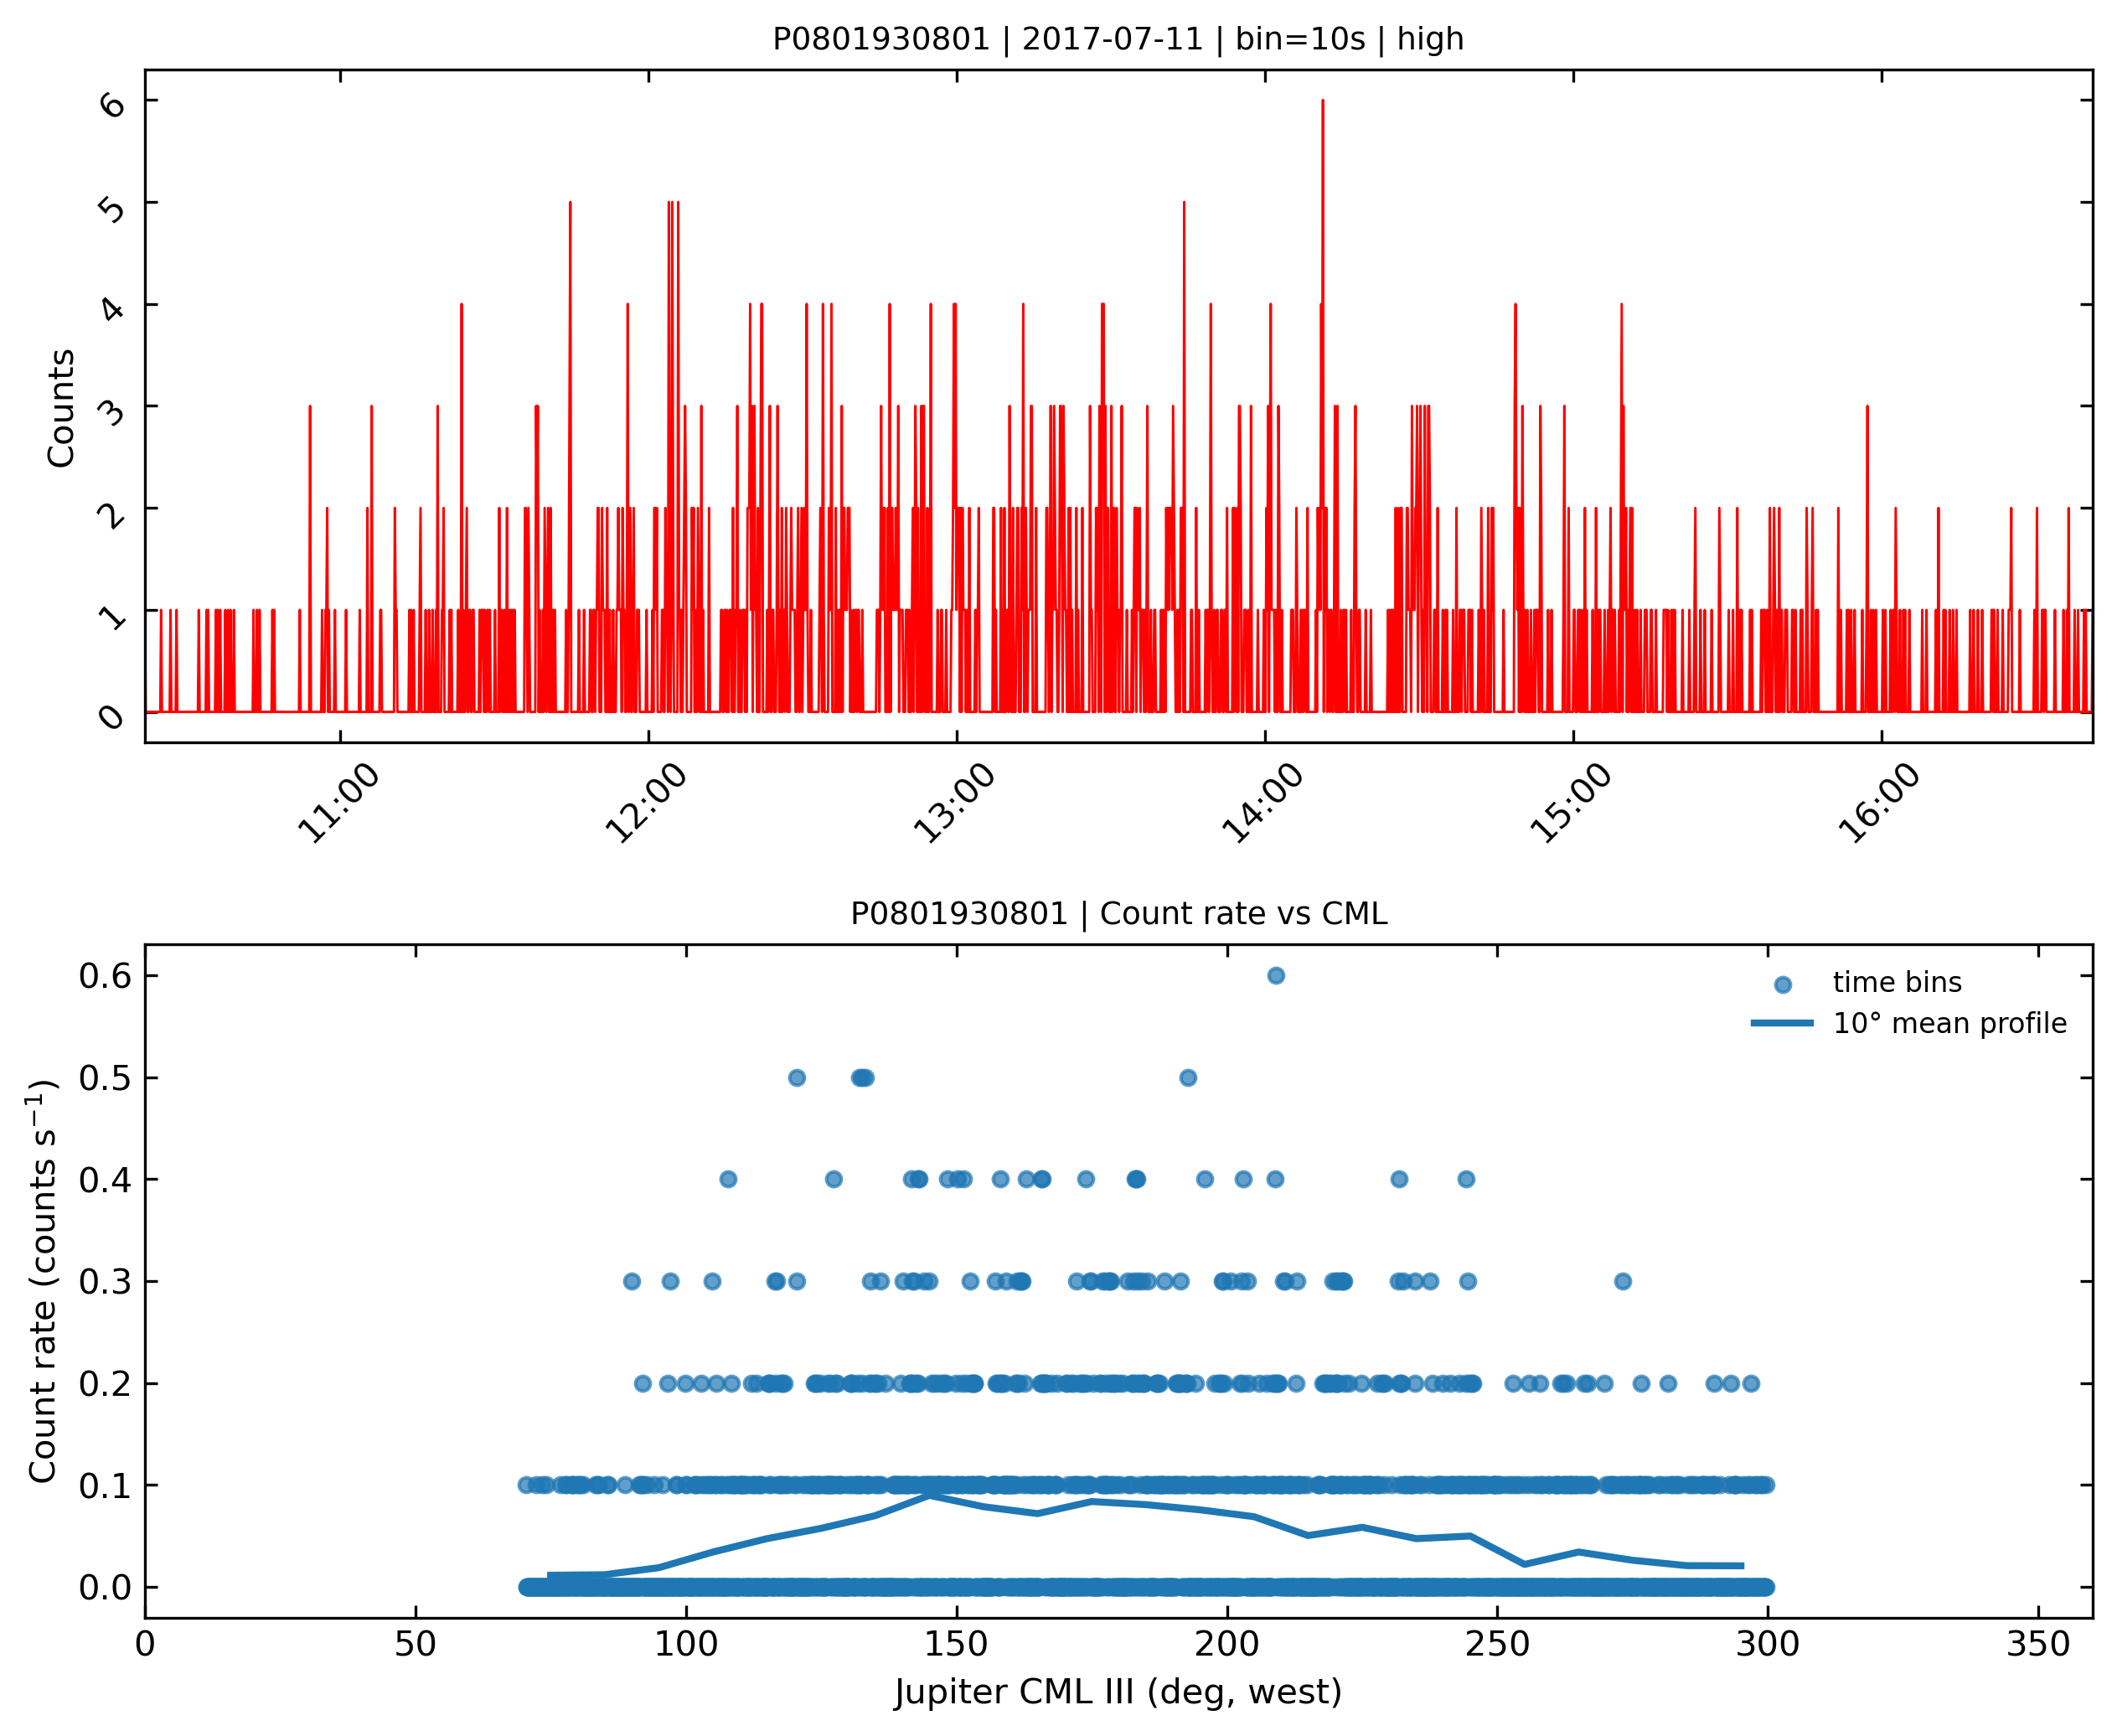

Finished P0801930801 | seg_bin=10s | category=high | segment=2


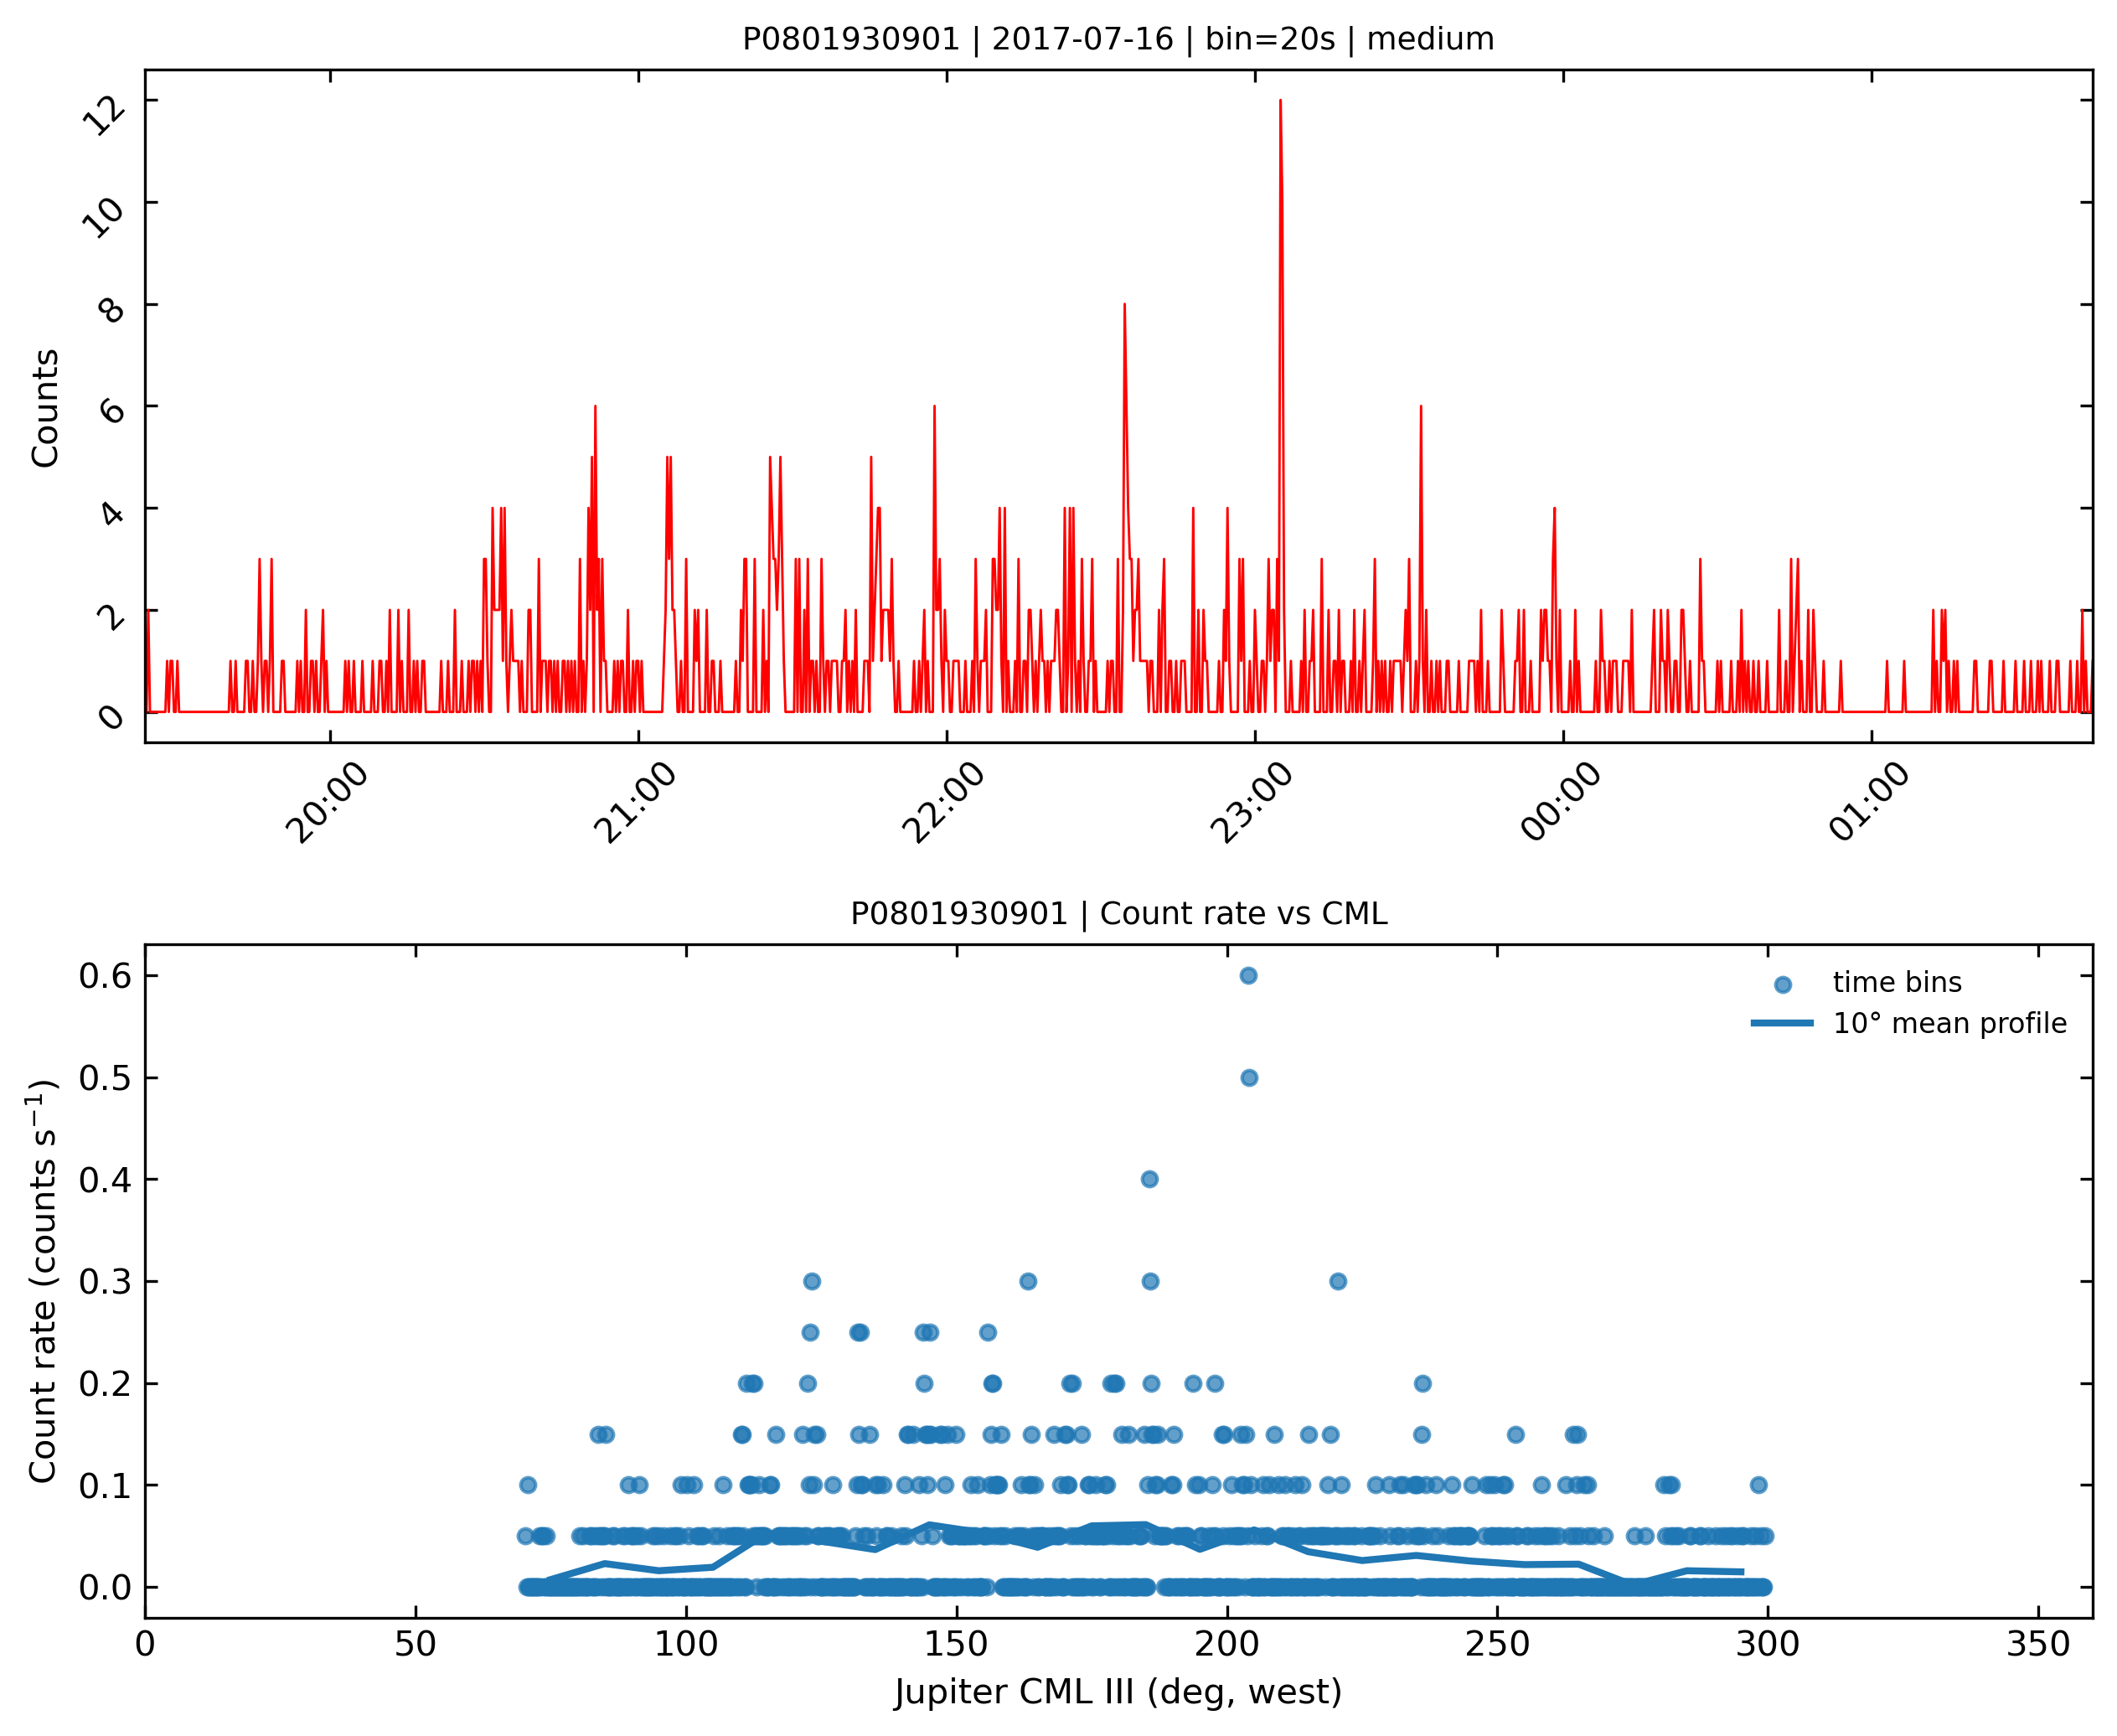

Finished P0801930901 | seg_bin=20s | category=medium | segment=1


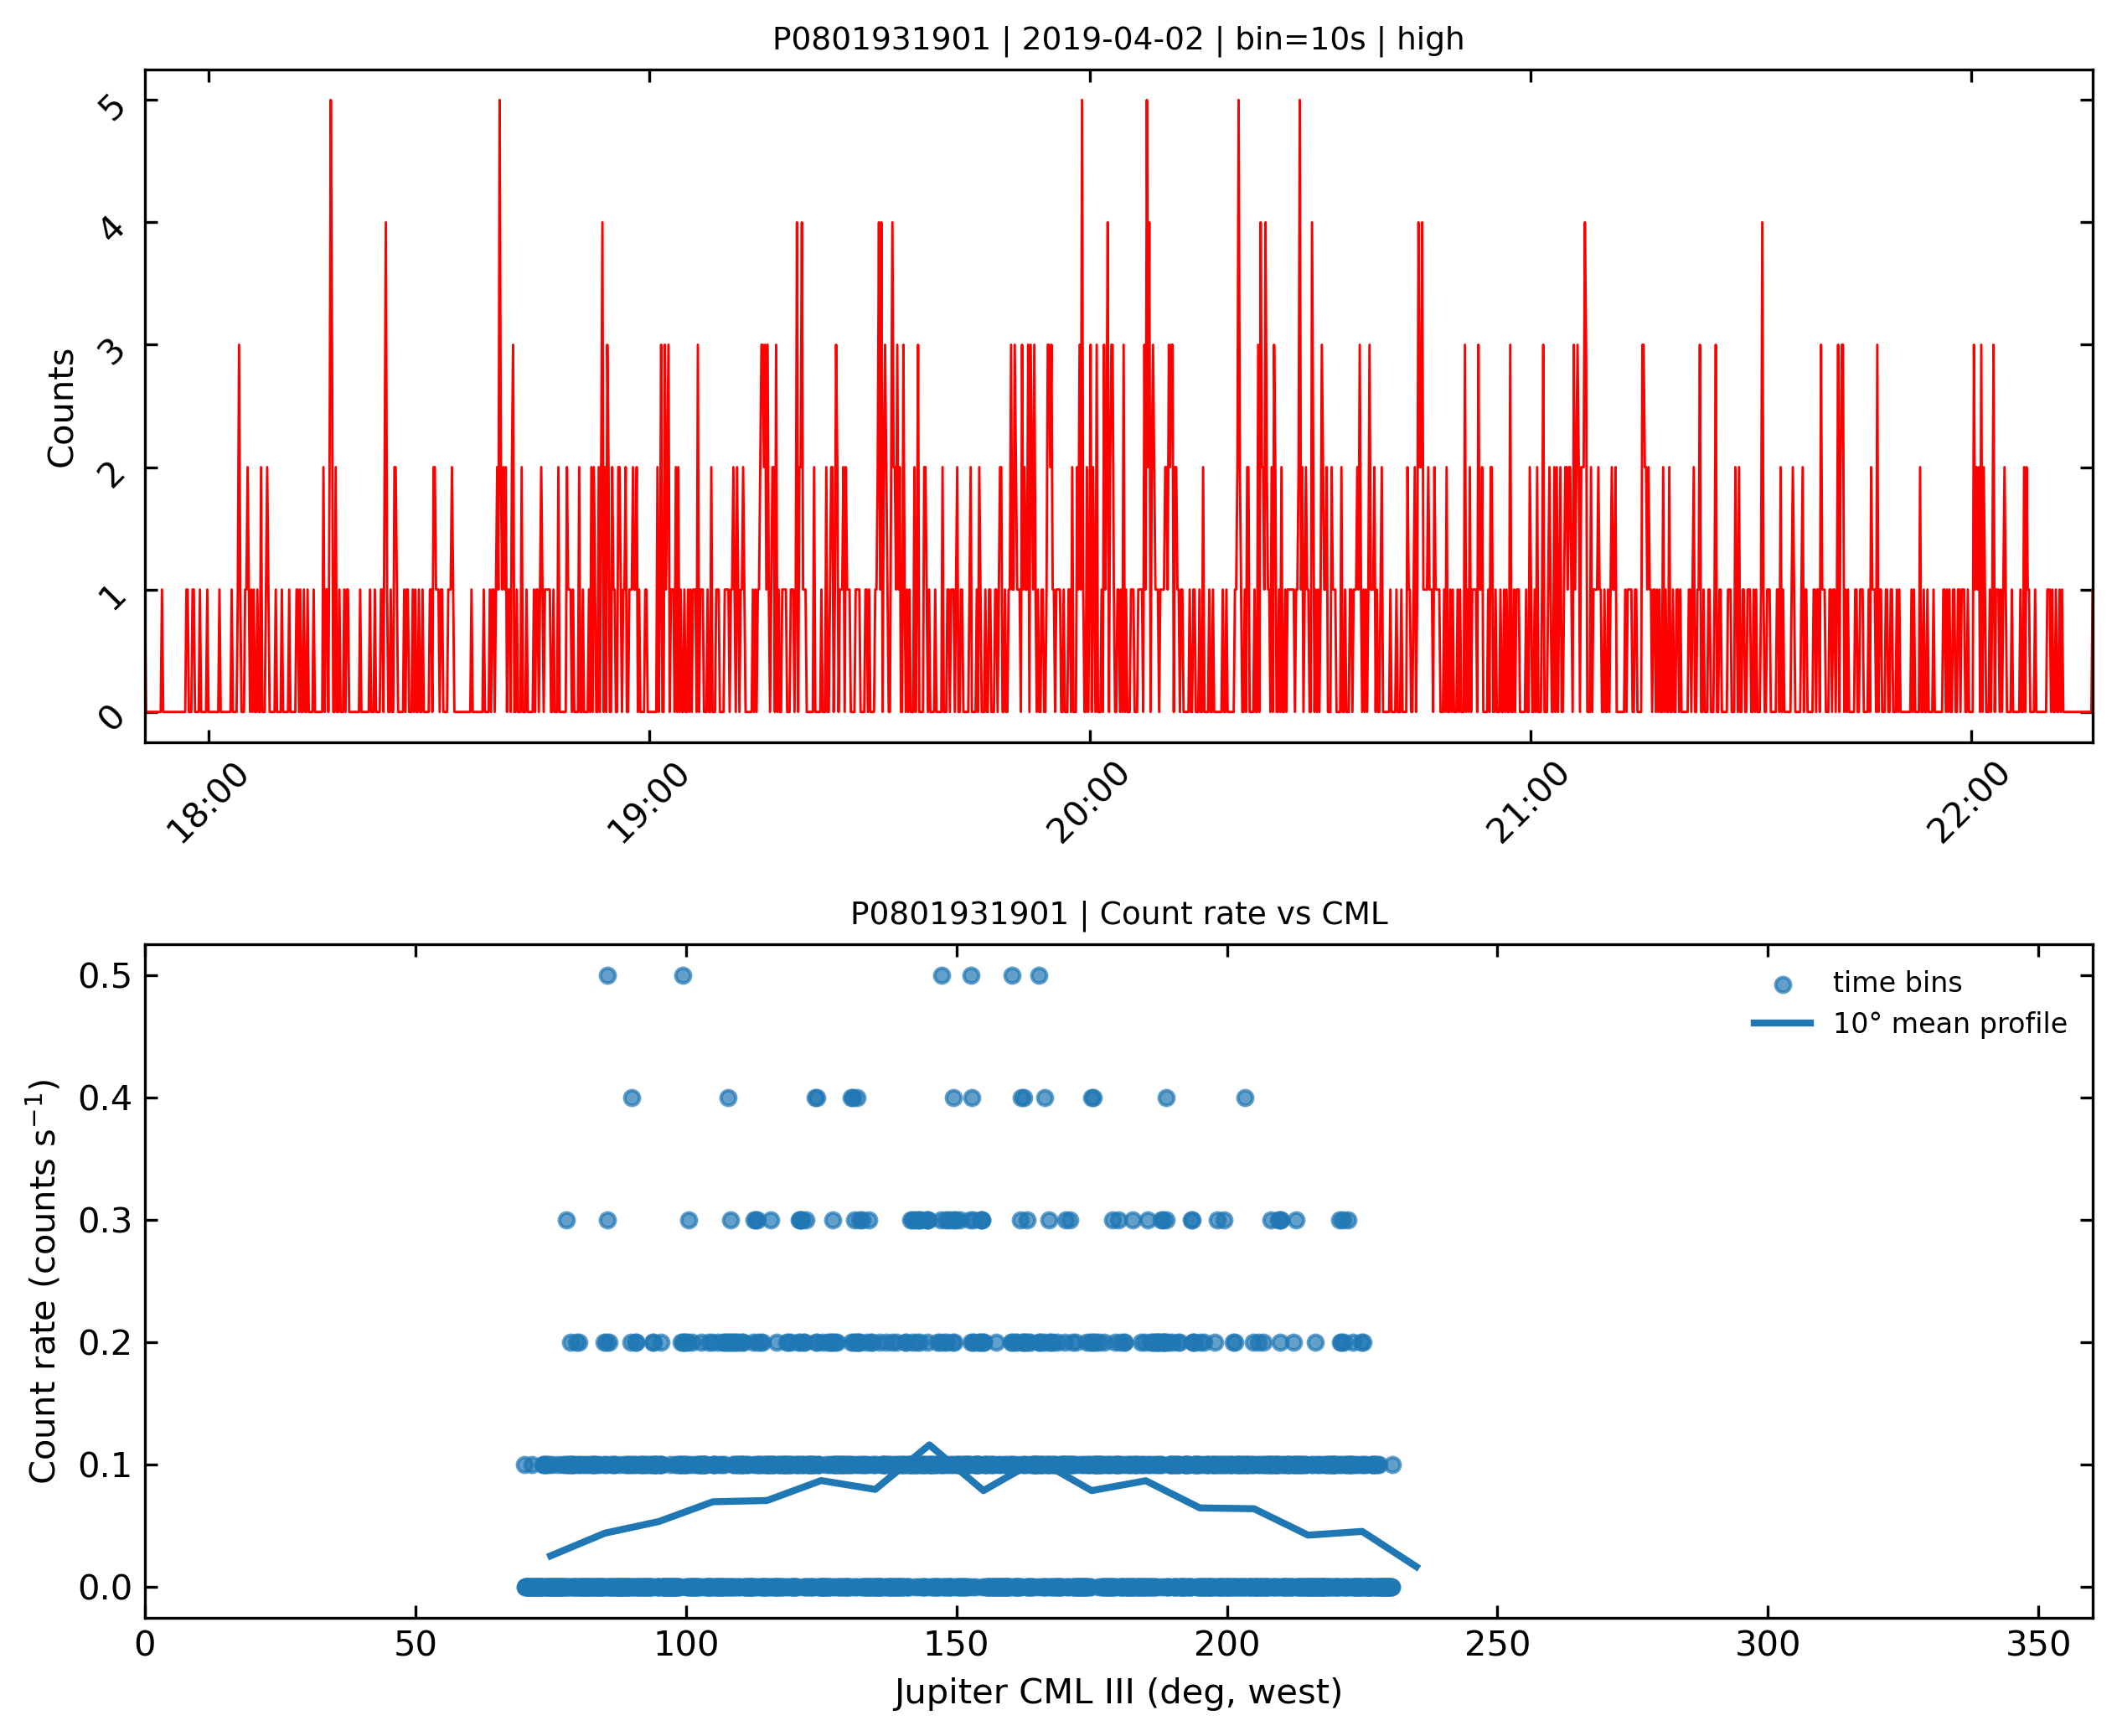

Finished P0801931901 | seg_bin=10s | category=high | segment=3


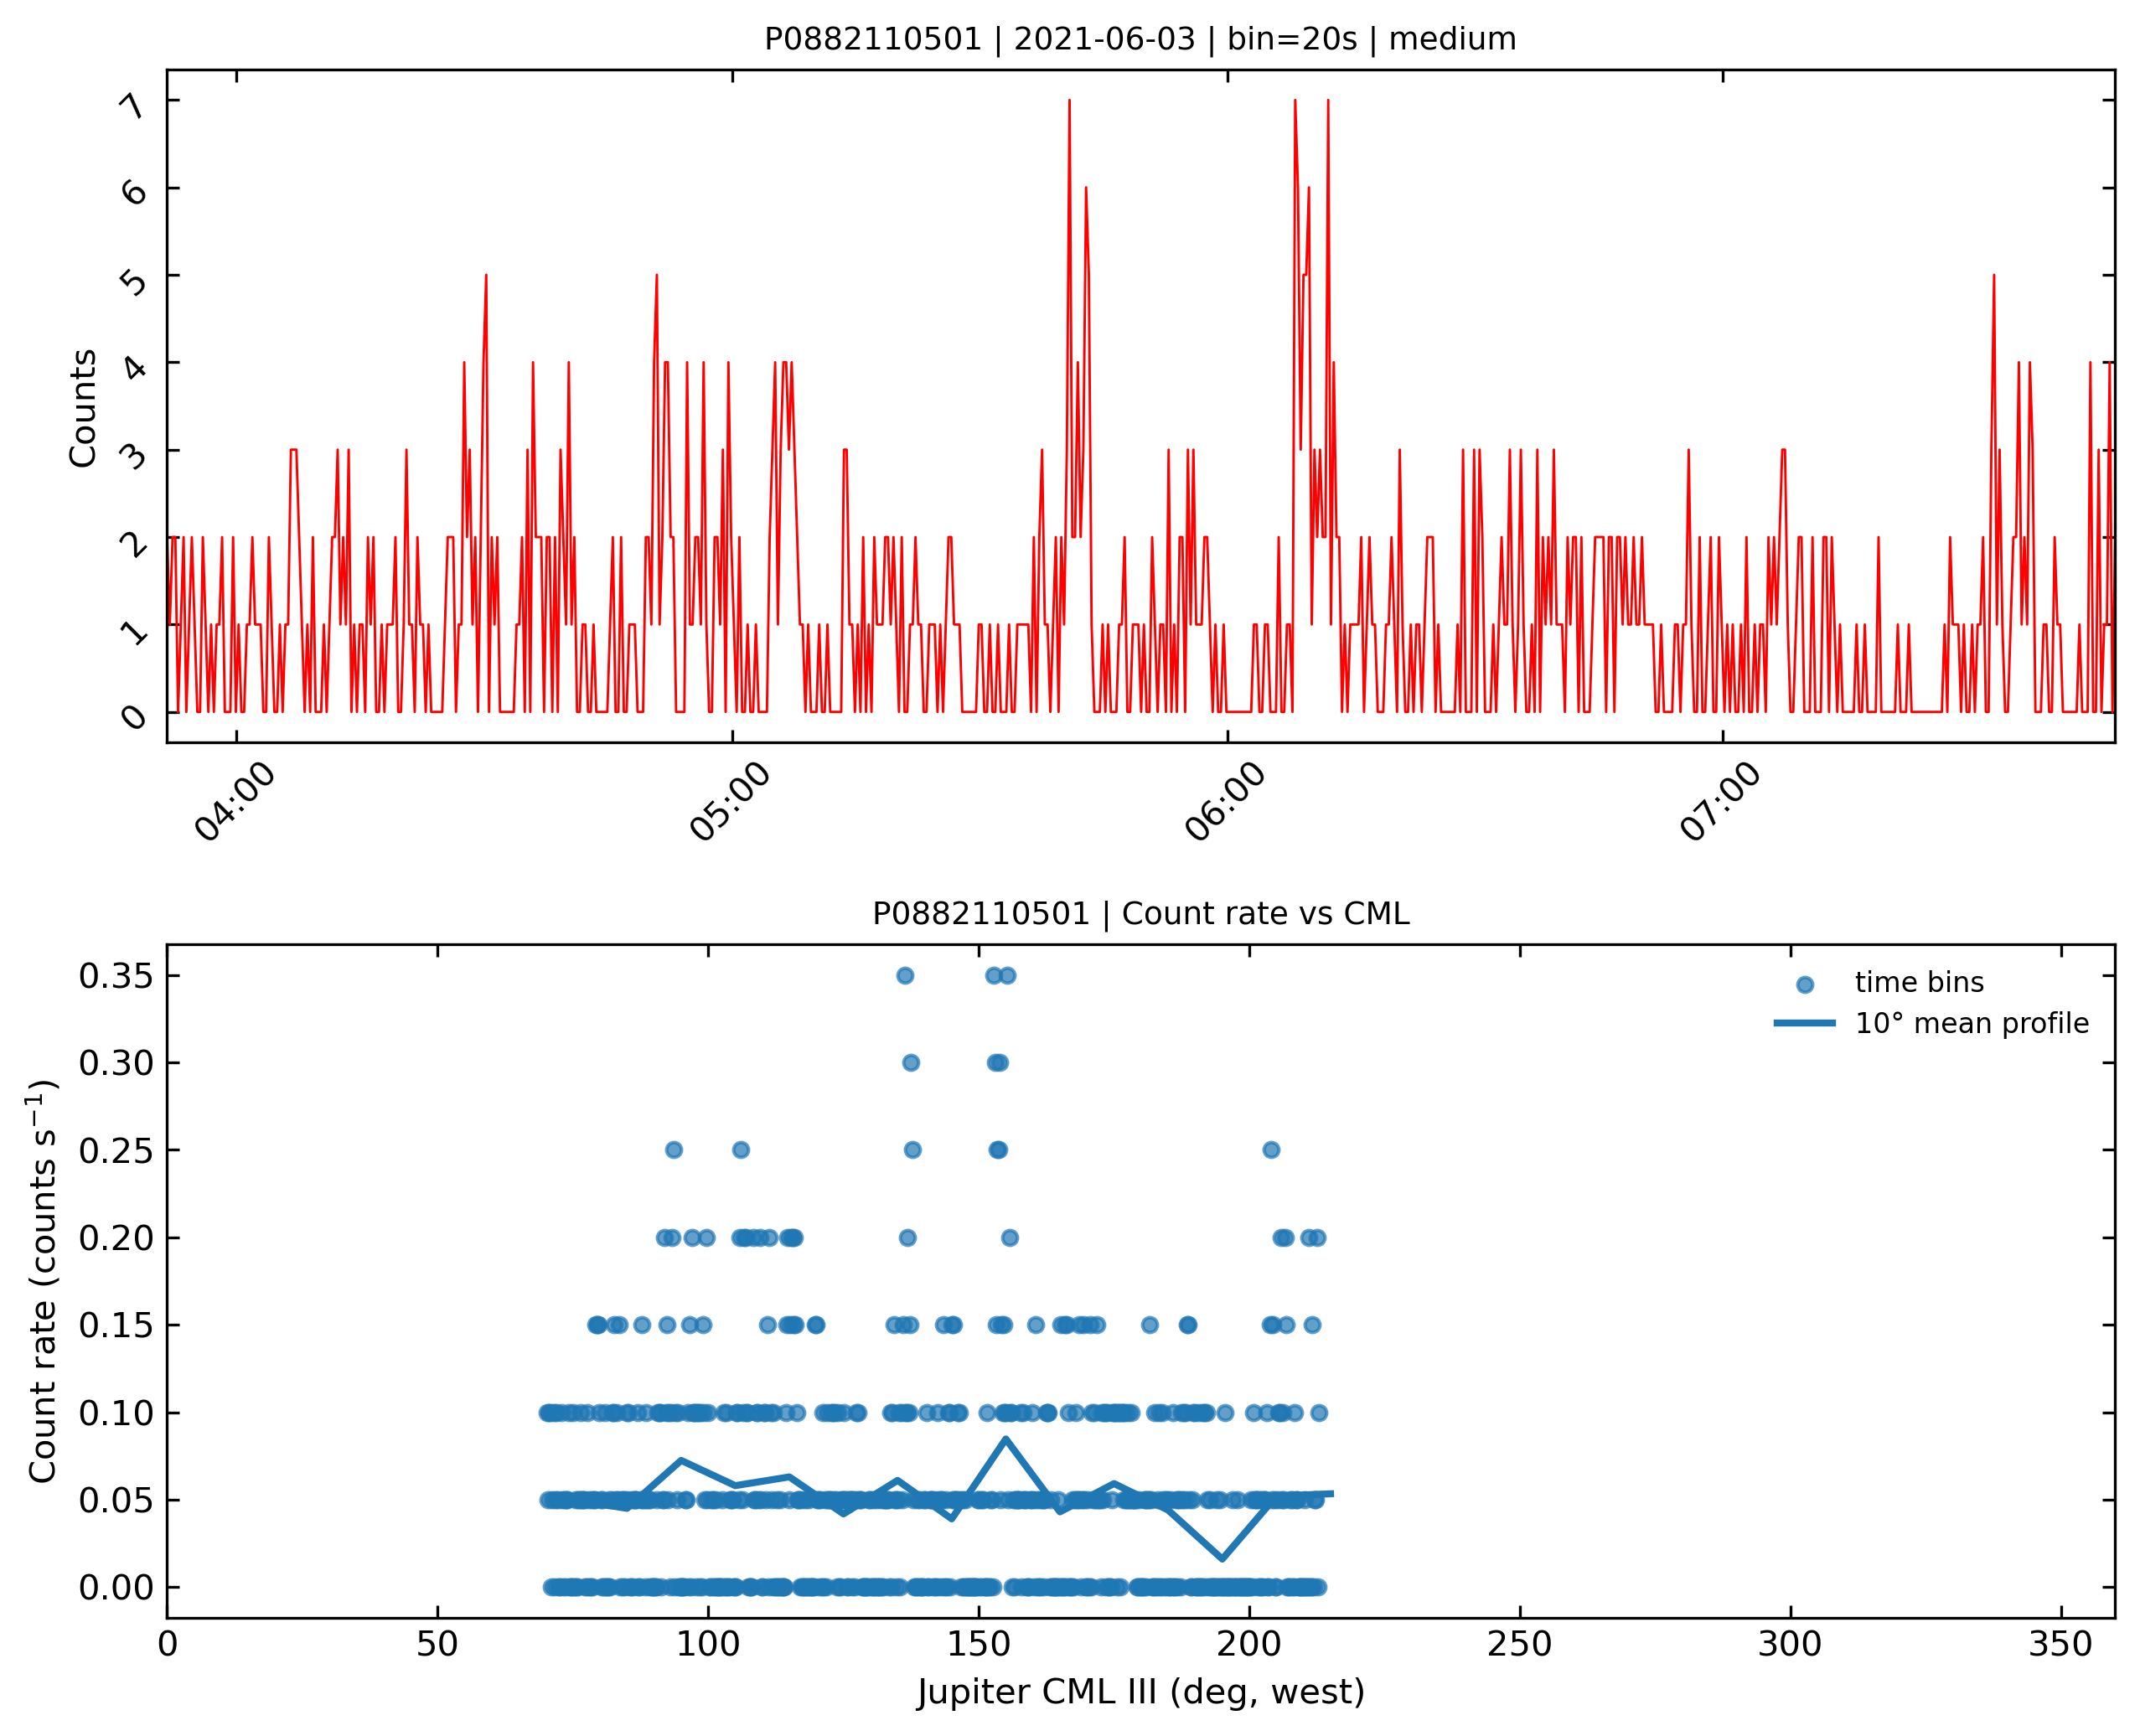

Finished P0882110501 | seg_bin=20s | category=medium | segment=3


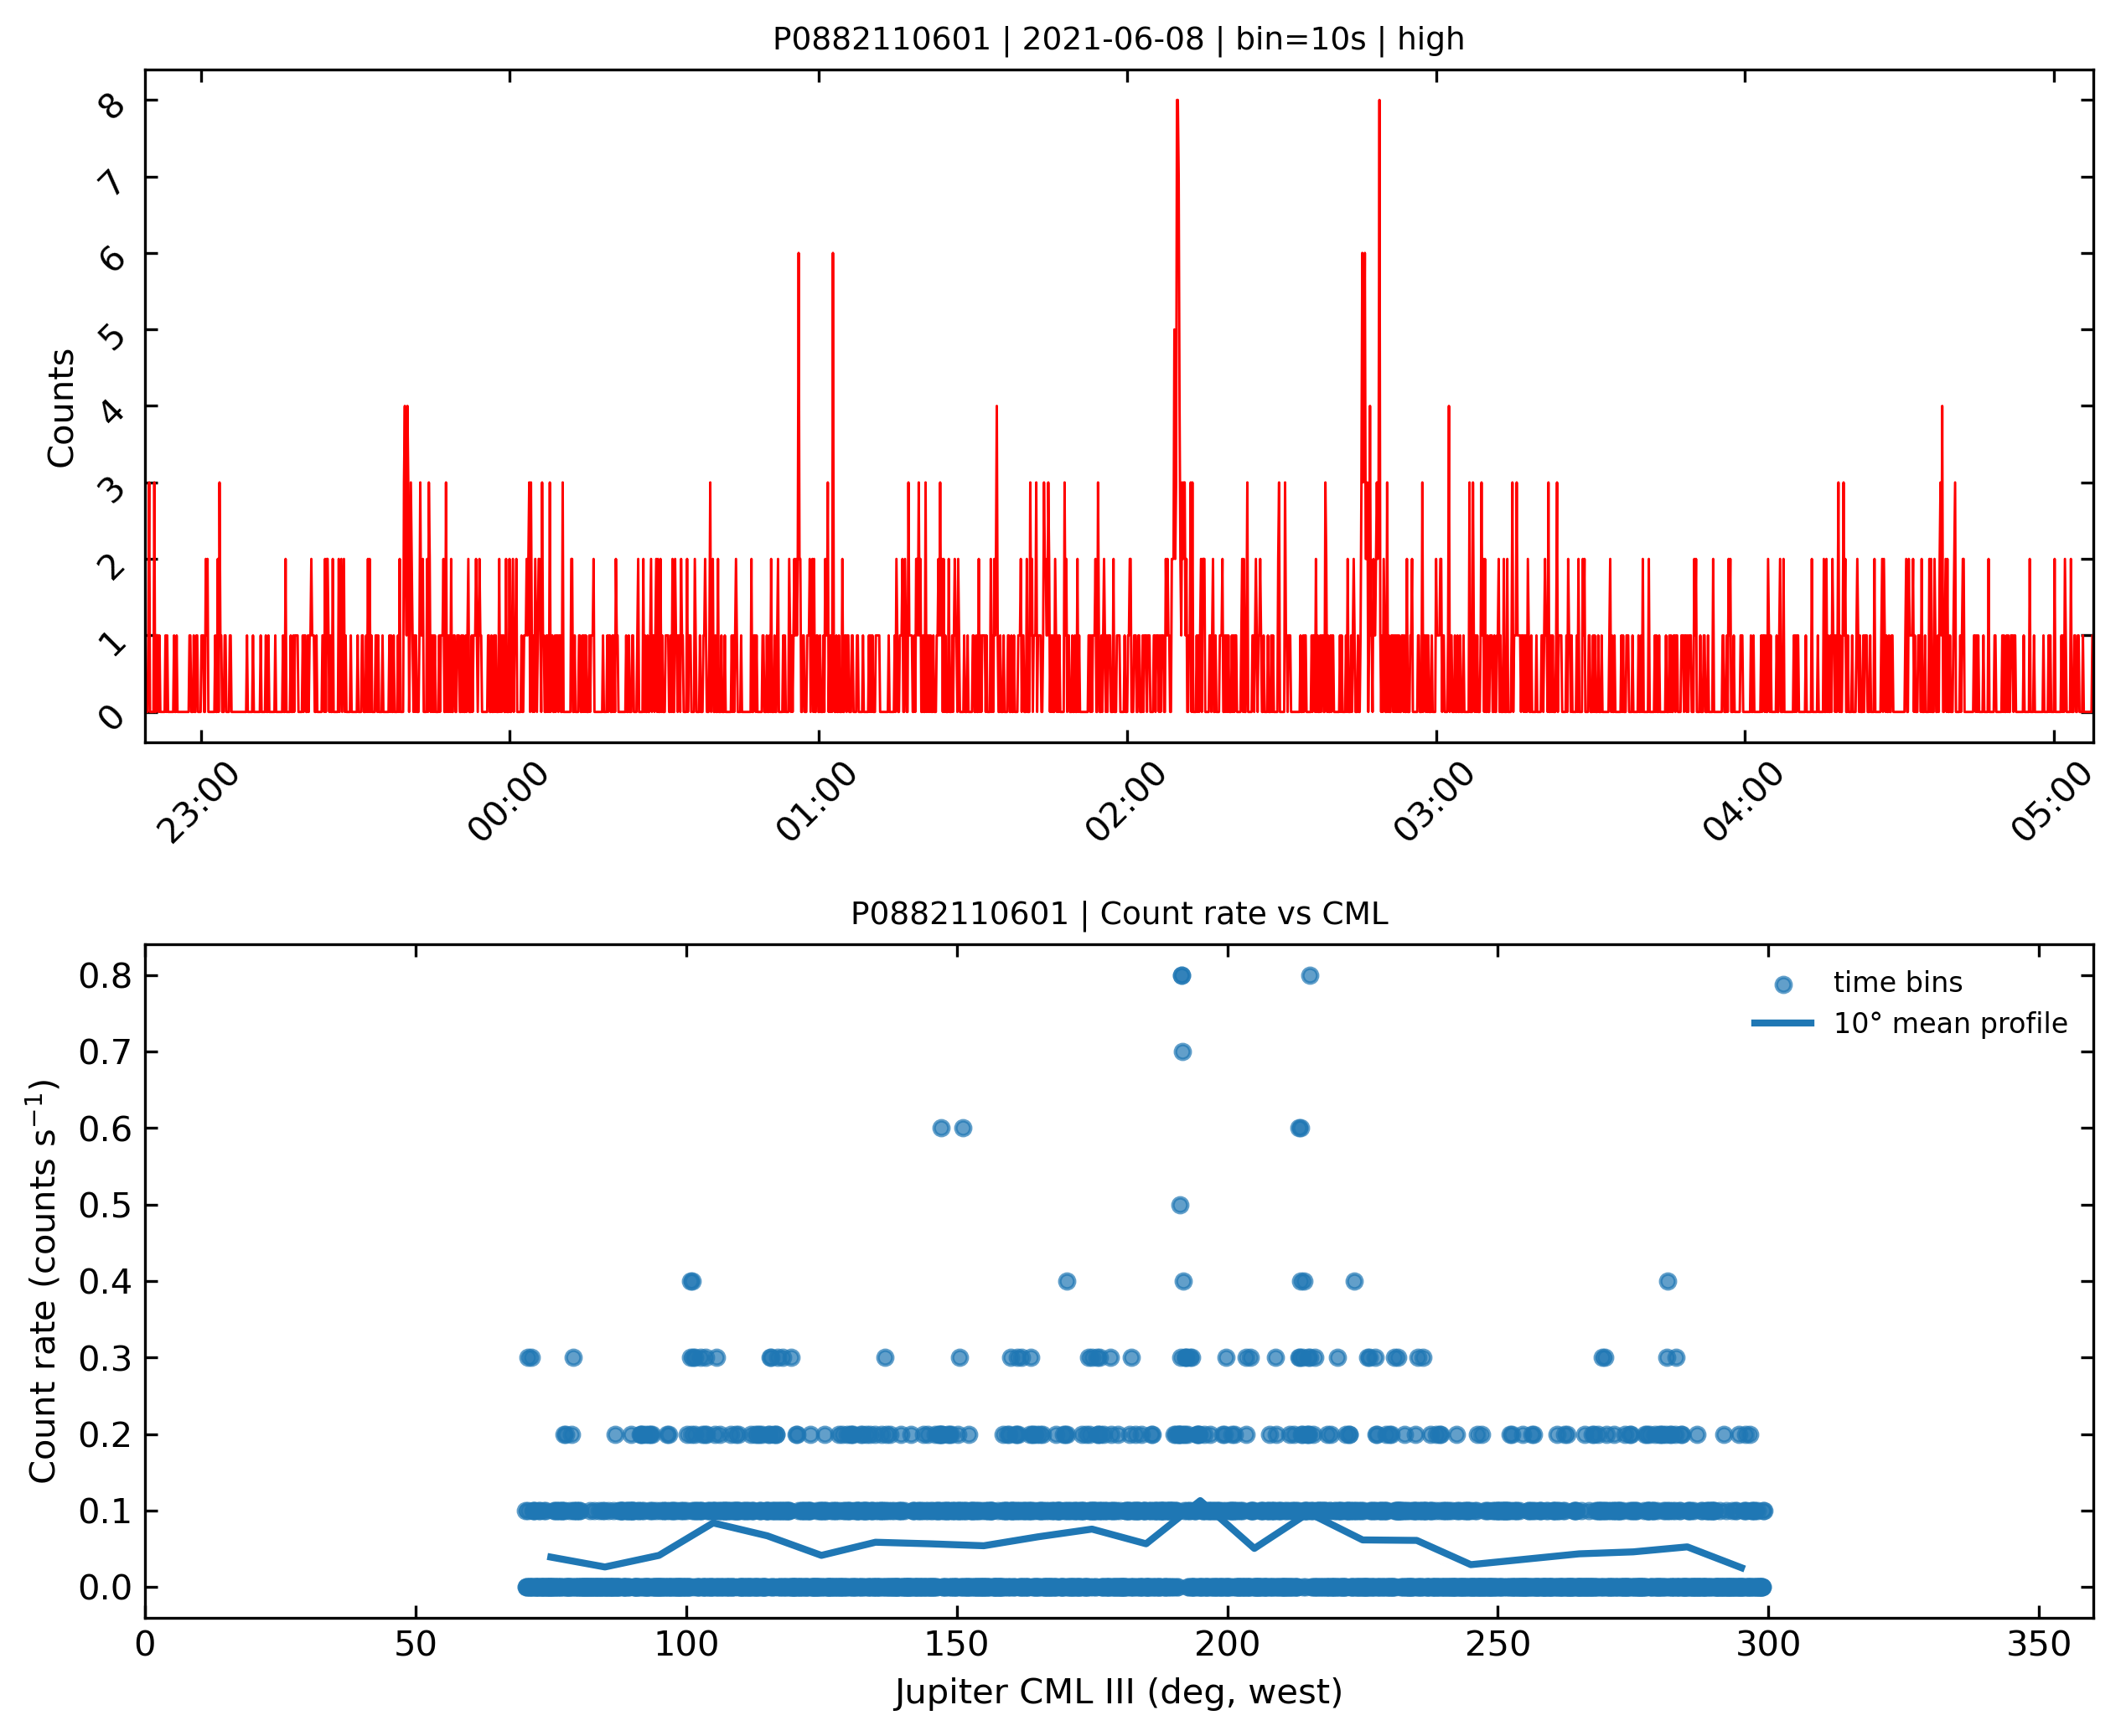

Finished P0882110601 | seg_bin=10s | category=high | segment=5


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from typing import Optional, Dict, Tuple, List

from astropy.table import Table
from astropy.time import Time
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
import astropy.units as u

from matplotlib.dates import DateFormatter, HourLocator
import spiceypy as sp
import jplephem
import warnings
warnings.filterwarnings("ignore")


# ─── USER SETTINGS ────────────────────────────────────────────────────────────
ident = ['P0801930801', 'P0801930901', 'P0801931901', 'P0882110501', 'P0882110601']
TARGET_SEGMENTS = {
    'P0801930801': 2,
    'P0801930901': 1,
    'P0801931901': 3,
    'P0882110501': 3,
    'P0882110601': 5
}

base_bin_size = 10
data_dir = 'Data_Files/Fenn_Data/'

# SPICE kernels needed at minimum:
#   naif0012.tls
#   de440.bsp
#   pck00011.tpc   (or pck00010.tpc if that is what you already use)
#   jup365.bsp
kernel_dir = "SPICE KERNELS"


# ─── SPICE SETUP ──────────────────────────────────────────────────────────────
def ensure_spice_kernels_loaded(kernel_dir: str):
    """
    Load the SPICE kernels needed for Jupiter/Earth geometry.
    """
    required = ["naif0012.tls", "de440.bsp", "jup365.bsp"]
    # prefer pck00011, fallback to pck00010
    pck11 = os.path.join(kernel_dir, "pck00011.tpc")
    pck10 = os.path.join(kernel_dir, "pck00010.tpc")

    sp.kclear()

    for fname in required:
        path = os.path.join(kernel_dir, fname)
        if not os.path.exists(path):
            raise FileNotFoundError(f"Missing SPICE kernel: {path}")
        sp.furnsh(path)

    if os.path.exists(pck11):
        sp.furnsh(pck11)
    elif os.path.exists(pck10):
        sp.furnsh(pck10)
    else:
        raise FileNotFoundError(
            f"Need either {os.path.join(kernel_dir, 'pck00011.tpc')} "
            f"or {os.path.join(kernel_dir, 'pck00010.tpc')}"
        )


# ─── IO + PREP ────────────────────────────────────────────────────────────────
def load_combined_times(obs_id: str, data_dir: str):
    """
    Read all three EPIC cameras, correct for Jupiter–Earth light travel time,
    and return:
      times_datetime : ndarray[datetime]
      times_cxcsec   : ndarray[float]

    This matches your original approach: XMM approximated as Earth-based.
    """
    files = [f'{data_dir}EPIC_{obs_id}_{cam}_North_RFT.fit' for cam in ['PN', 'M1', 'M2']]
    list_dt, list_cxc = [], []

    for file in files:
        data = Table.read(file, format="fits")

        t = Time(data['TIME'], format='cxcsec', scale='tt')
        with solar_system_ephemeris.set('de432s'):
            jup = get_body_barycentric('jupiter', t)
            xmm = get_body_barycentric('earth', t)  # approximate XMM as Earth-based

        distance_au = (jup - xmm).norm()
        light_time_s = (distance_au.to('m') / c).to('s').value

        corrected_t = t - light_time_s * u.s
        list_dt.append(corrected_t.datetime)
        list_cxc.append(corrected_t.cxcsec)

    return np.hstack(list_dt), np.hstack(list_cxc)


def find_gaps(times_cxcsec: np.ndarray, threshold: float = 3600.0):
    """
    Identify indices where the gap between consecutive times > threshold seconds.
    Returns:
      gaps    : list of (gap_start, gap_end) in cxcsec
      indices : ndarray of indices i such that times[i+1]-times[i] > threshold
    """
    dt = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    gaps = [(times_cxcsec[i], times_cxcsec[i + 1]) for i in indices]
    return gaps, indices


# ─── BINNING ──────────────────────────────────────────────────────────────────
def bin_photon_times(photon_times: np.ndarray, bin_size: float):
    """
    Bin photon_times (CXC seconds) into bins of width=bin_size seconds.
    Returns:
      centers_cxcsec, counts
    """
    start = float(np.nanmin(photon_times))
    end = float(np.nanmax(photon_times))
    bins = np.arange(start, end + bin_size, bin_size)
    counts, edges = np.histogram(photon_times, bins=bins)
    centers = edges[:-1] + 0.5 * bin_size
    return centers, counts


def categorize_segment(counts: np.ndarray, low_thresh: float = 300, high_thresh: float = 1000):
    total = float(np.sum(counts))
    if total < low_thresh:
        return 'low'
    elif total < high_thresh:
        return 'medium'
    return 'high'


def dynamic_bin_size(category: str, base_bin: int = 120):
    if category == 'low':
        return base_bin * 4
    elif category == 'medium':
        return base_bin * 2
    return base_bin


def prepare_segment_bins(raw_segment: np.ndarray, base_bin: int):
    """
    1) initial bin with base_bin to categorise
    2) choose seg_bin via dynamic_bin_size
    3) re-bin with seg_bin
    """
    _, counts0 = bin_photon_times(raw_segment, base_bin)
    category = categorize_segment(counts0)

    seg_bin = dynamic_bin_size(category, base_bin)
    hist_centers, hist_counts = bin_photon_times(raw_segment, seg_bin)
    return seg_bin, hist_centers, hist_counts, category


# ─── TIME CONVERSION FOR SPICE ────────────────────────────────────────────────
def cxcsec_to_et(cxcsec: np.ndarray) -> np.ndarray:
    """
    Convert CXC TT seconds to SPICE ET ~ TDB seconds past J2000.

    Uses astropy to convert TT -> TDB, then expresses it as seconds from JD 2451545.0.
    """
    t = Time(cxcsec, format='cxcsec', scale='tt')
    t_tdb = t.tdb
    et = (t_tdb.jd - 2451545.0) * 86400.0
    return np.asarray(et, dtype=float)


# ─── JUPITER CML CALCULATION ──────────────────────────────────────────────────
def cml_from_et(et_array: np.ndarray) -> np.ndarray:
    """
    Compute Jupiter CML (System III, west longitude) for each ET.

    Method:
      - get Earth position relative to Jupiter in IAU_JUPITER body-fixed frame
      - convert that observer direction to longitude
      - interpret the sub-observer longitude as the central meridian longitude

    SPICE longitudes in IAU_JUPITER are east-positive.
    Jupiter CML is usually quoted as west longitude, so:
        CML_west = (360 - lon_east_deg) % 360

    If your convention appears flipped relative to your other products,
    swap to:
        cml_west = lon_east_deg % 360
    """
    cml_deg = np.empty(len(et_array), dtype=float)

    for i, et in enumerate(et_array):
        # Earth as seen from Jupiter, in Jupiter body-fixed frame
        state, _ = sp.spkezr("EARTH", float(et), "IAU_JUPITER", "NONE", "JUPITER")
        x, y, z = state[:3]

        r, lon_east_rad, lat_rad = sp.reclat(np.array([x, y, z]))
        lon_east_deg = np.degrees(lon_east_rad) % 360.0

        cml_west = (360.0 - lon_east_deg) % 360.0
        cml_deg[i] = cml_west

    return cml_deg


def compute_binned_cml(hist_centers_cxcsec: np.ndarray) -> np.ndarray:
    """
    Compute CML for each lightcurve bin centre.
    """
    et = cxcsec_to_et(hist_centers_cxcsec)
    return cml_from_et(et)


# ─── PHASE BINNING IN CML ─────────────────────────────────────────────────────
def phase_bin_cml(cml_deg: np.ndarray, values: np.ndarray, cml_bin_deg: float = 10.0):
    """
    Phase-bin a quantity versus CML in [0,360).

    Returns:
      bin_centers_deg
      mean_values
      n_per_bin
    """
    edges = np.arange(0.0, 360.0 + cml_bin_deg, cml_bin_deg)
    centers = 0.5 * (edges[:-1] + edges[1:])

    inds = np.digitize(cml_deg % 360.0, edges) - 1
    inds = np.clip(inds, 0, len(centers) - 1)

    sums = np.zeros(len(centers), dtype=float)
    nums = np.zeros(len(centers), dtype=int)

    for i, idx in enumerate(inds):
        if np.isfinite(values[i]):
            sums[idx] += values[i]
            nums[idx] += 1

    mean_vals = np.full(len(centers), np.nan, dtype=float)
    good = nums > 0
    mean_vals[good] = sums[good] / nums[good]

    return centers, mean_vals, nums


# ─── PLOTTING ─────────────────────────────────────────────────────────────────
def plot_lightcurve_subplot(ax, hist_centers, hist_counts, seg_bin, category,
                            obs_id, start_iso, end_iso):
    hist_dt = Time(hist_centers, format='cxcsec').datetime
    ax.plot(hist_dt, hist_counts, c='red', lw=0.7)

    title = f"{obs_id} | {start_iso[:10]} | bin={int(seg_bin)}s | {category}"
    ax.set_title(title, fontsize=9)

    ax.set_ylabel("Counts")
    ax.set_xlim(hist_dt[0], hist_dt[-1])

    ax.xaxis.set_major_locator(HourLocator(interval=1))
    ax.xaxis.set_major_formatter(DateFormatter('%H:%M'))
    ax.tick_params(rotation=45, direction='in', top=True, right=True)


def plot_cml_scatter_and_profile(ax, cml_deg, rates, cml_bin_centers, rate_profile, cml_bin_deg, obs_id):
    ax.scatter(cml_deg, rates, s=18, alpha=0.7, label='time bins')

    good = np.isfinite(rate_profile)
    ax.plot(cml_bin_centers[good], rate_profile[good], lw=2.0, label=f'{cml_bin_deg:.0f}° mean profile')

    ax.set_xlim(0, 360)
    ax.set_xlabel("Jupiter CML III (deg, west)")
    ax.set_ylabel("Count rate (counts s$^{-1}$)")
    ax.set_title(f"{obs_id} | Count rate vs CML", fontsize=9)
    ax.tick_params(direction='in', top=True, right=True)
    ax.legend(frameon=False, fontsize=8)


# ─── FINAL WRAPPER ────────────────────────────────────────────────────────────
def run_xmm_cml_segment_analysis(
    obs_id: str,
    data_dir: str = "Data_Files/Fenn_Data/",
    kernel_dir: str = "SPICE_KERNELS",
    base_bin_size: int = 10,
    gap_threshold_s: int = 3600,
    target_segments: Optional[Dict[str, int]] = None,
    cml_bin_deg: float = 10.0,
    save_path: Optional[str] = None,
    show: bool = True,
    dpi: int = 200,
    make_time_panel: bool = True,
):
    """
    End-to-end wrapper for:
      - load combined EPIC photon times
      - gap-split into segments
      - optional 1-based segment selection from target_segments
      - dynamic binning
      - compute CML at each lightcurve bin centre
      - plot counts/rate versus CML

    Returns a dictionary of useful outputs.
    """
    if target_segments is None:
        target_segments = {}

    ensure_spice_kernels_loaded(kernel_dir)

    # Load + sort
    _, times_cxc = load_combined_times(obs_id, data_dir)
    if times_cxc.size < 10:
        raise ValueError(f"{obs_id}: not enough events after loading (N={times_cxc.size}).")

    order = np.argsort(times_cxc)
    t_sorted = times_cxc[order]

    # Gap split
    _, gap_idx = find_gaps(t_sorted, threshold=float(gap_threshold_s))
    split_pts = np.concatenate(([0], gap_idx + 1, [len(t_sorted)]))

    all_segments = []
    all_seg_times_iso = []
    for i in range(len(split_pts) - 1):
        seg = t_sorted[split_pts[i]: split_pts[i + 1]]
        if seg.size > 5:
            all_segments.append(seg)
            all_seg_times_iso.append((
                Time(seg[0], format='cxcsec').iso,
                Time(seg[-1], format='cxcsec').iso
            ))

    if len(all_segments) == 0:
        raise ValueError(f"{obs_id}: no valid segments after gap-splitting.")

    # Optional segment selection (1-based)
    selected_1based = target_segments.get(obs_id, None)
    if selected_1based is not None:
        k = selected_1based - 1
        if not (0 <= k < len(all_segments)):
            raise ValueError(
                f"{obs_id}: requested segment {selected_1based} but only {len(all_segments)} segments exist."
            )
        seg = all_segments[k]
        start_iso, end_iso = all_seg_times_iso[k]
    else:
        seg = all_segments[0]
        start_iso, end_iso = all_seg_times_iso[0]

    # Dynamic lightcurve binning
    seg_bin, hist_centers, hist_counts, category = prepare_segment_bins(seg, base_bin_size)
    hist_rates = hist_counts / float(seg_bin)

    # CML at each bin centre
    cml_deg = compute_binned_cml(hist_centers)

    # Phase-binned profile
    cml_bin_centers, rate_profile, n_per_cml_bin = phase_bin_cml(
        cml_deg, hist_rates, cml_bin_deg=cml_bin_deg
    )

    # Plot
    if make_time_panel:
        fig, (ax_lc, ax_cml) = plt.subplots(
            2, 1,
            figsize=(10, 8),
            dpi=dpi,
            gridspec_kw={"height_ratios": [2, 2], "hspace": 0.3}
        )

        plot_lightcurve_subplot(ax_lc, hist_centers, hist_counts, seg_bin, category, obs_id, start_iso, end_iso)
        ax_lc.set_xlabel("")

        plot_cml_scatter_and_profile(
            ax_cml, cml_deg, hist_rates, cml_bin_centers, rate_profile, cml_bin_deg, obs_id
        )

    else:
        fig, ax_cml = plt.subplots(figsize=(10, 4.8), dpi=dpi)
        plot_cml_scatter_and_profile(
            ax_cml, cml_deg, hist_rates, cml_bin_centers, rate_profile, cml_bin_deg, obs_id
        )

    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, bbox_inches="tight")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return {
        "obs_id": obs_id,
        "selected_segment_1based": selected_1based,
        "start_iso": start_iso,
        "end_iso": end_iso,
        "category": category,
        "seg_bin_s": seg_bin,
        "hist_centers_cxcsec": hist_centers,
        "hist_counts": hist_counts,
        "hist_rates": hist_rates,
        "cml_deg_west": cml_deg,
        "cml_bin_centers_deg": cml_bin_centers,
        "cml_rate_profile": rate_profile,
        "n_per_cml_bin": n_per_cml_bin,
        "n_segments_found": len(all_segments),
    }


# ─── BATCH DRIVER ─────────────────────────────────────────────────────────────
if __name__ == "__main__":
    for obs_id in ident:
        out = run_xmm_cml_segment_analysis(
            obs_id=obs_id,
            data_dir=data_dir,
            kernel_dir=kernel_dir,
            base_bin_size=base_bin_size,
            gap_threshold_s=3600,
            target_segments=TARGET_SEGMENTS,
            cml_bin_deg=10.0,
            save_path=f"{obs_id}_cml_profile.png",
            show=True,
            dpi=300,
            make_time_panel=True,
        )
        print(
            f"Finished {obs_id} | seg_bin={out['seg_bin_s']}s | "
            f"category={out['category']} | segment={out['selected_segment_1based']}"
        )

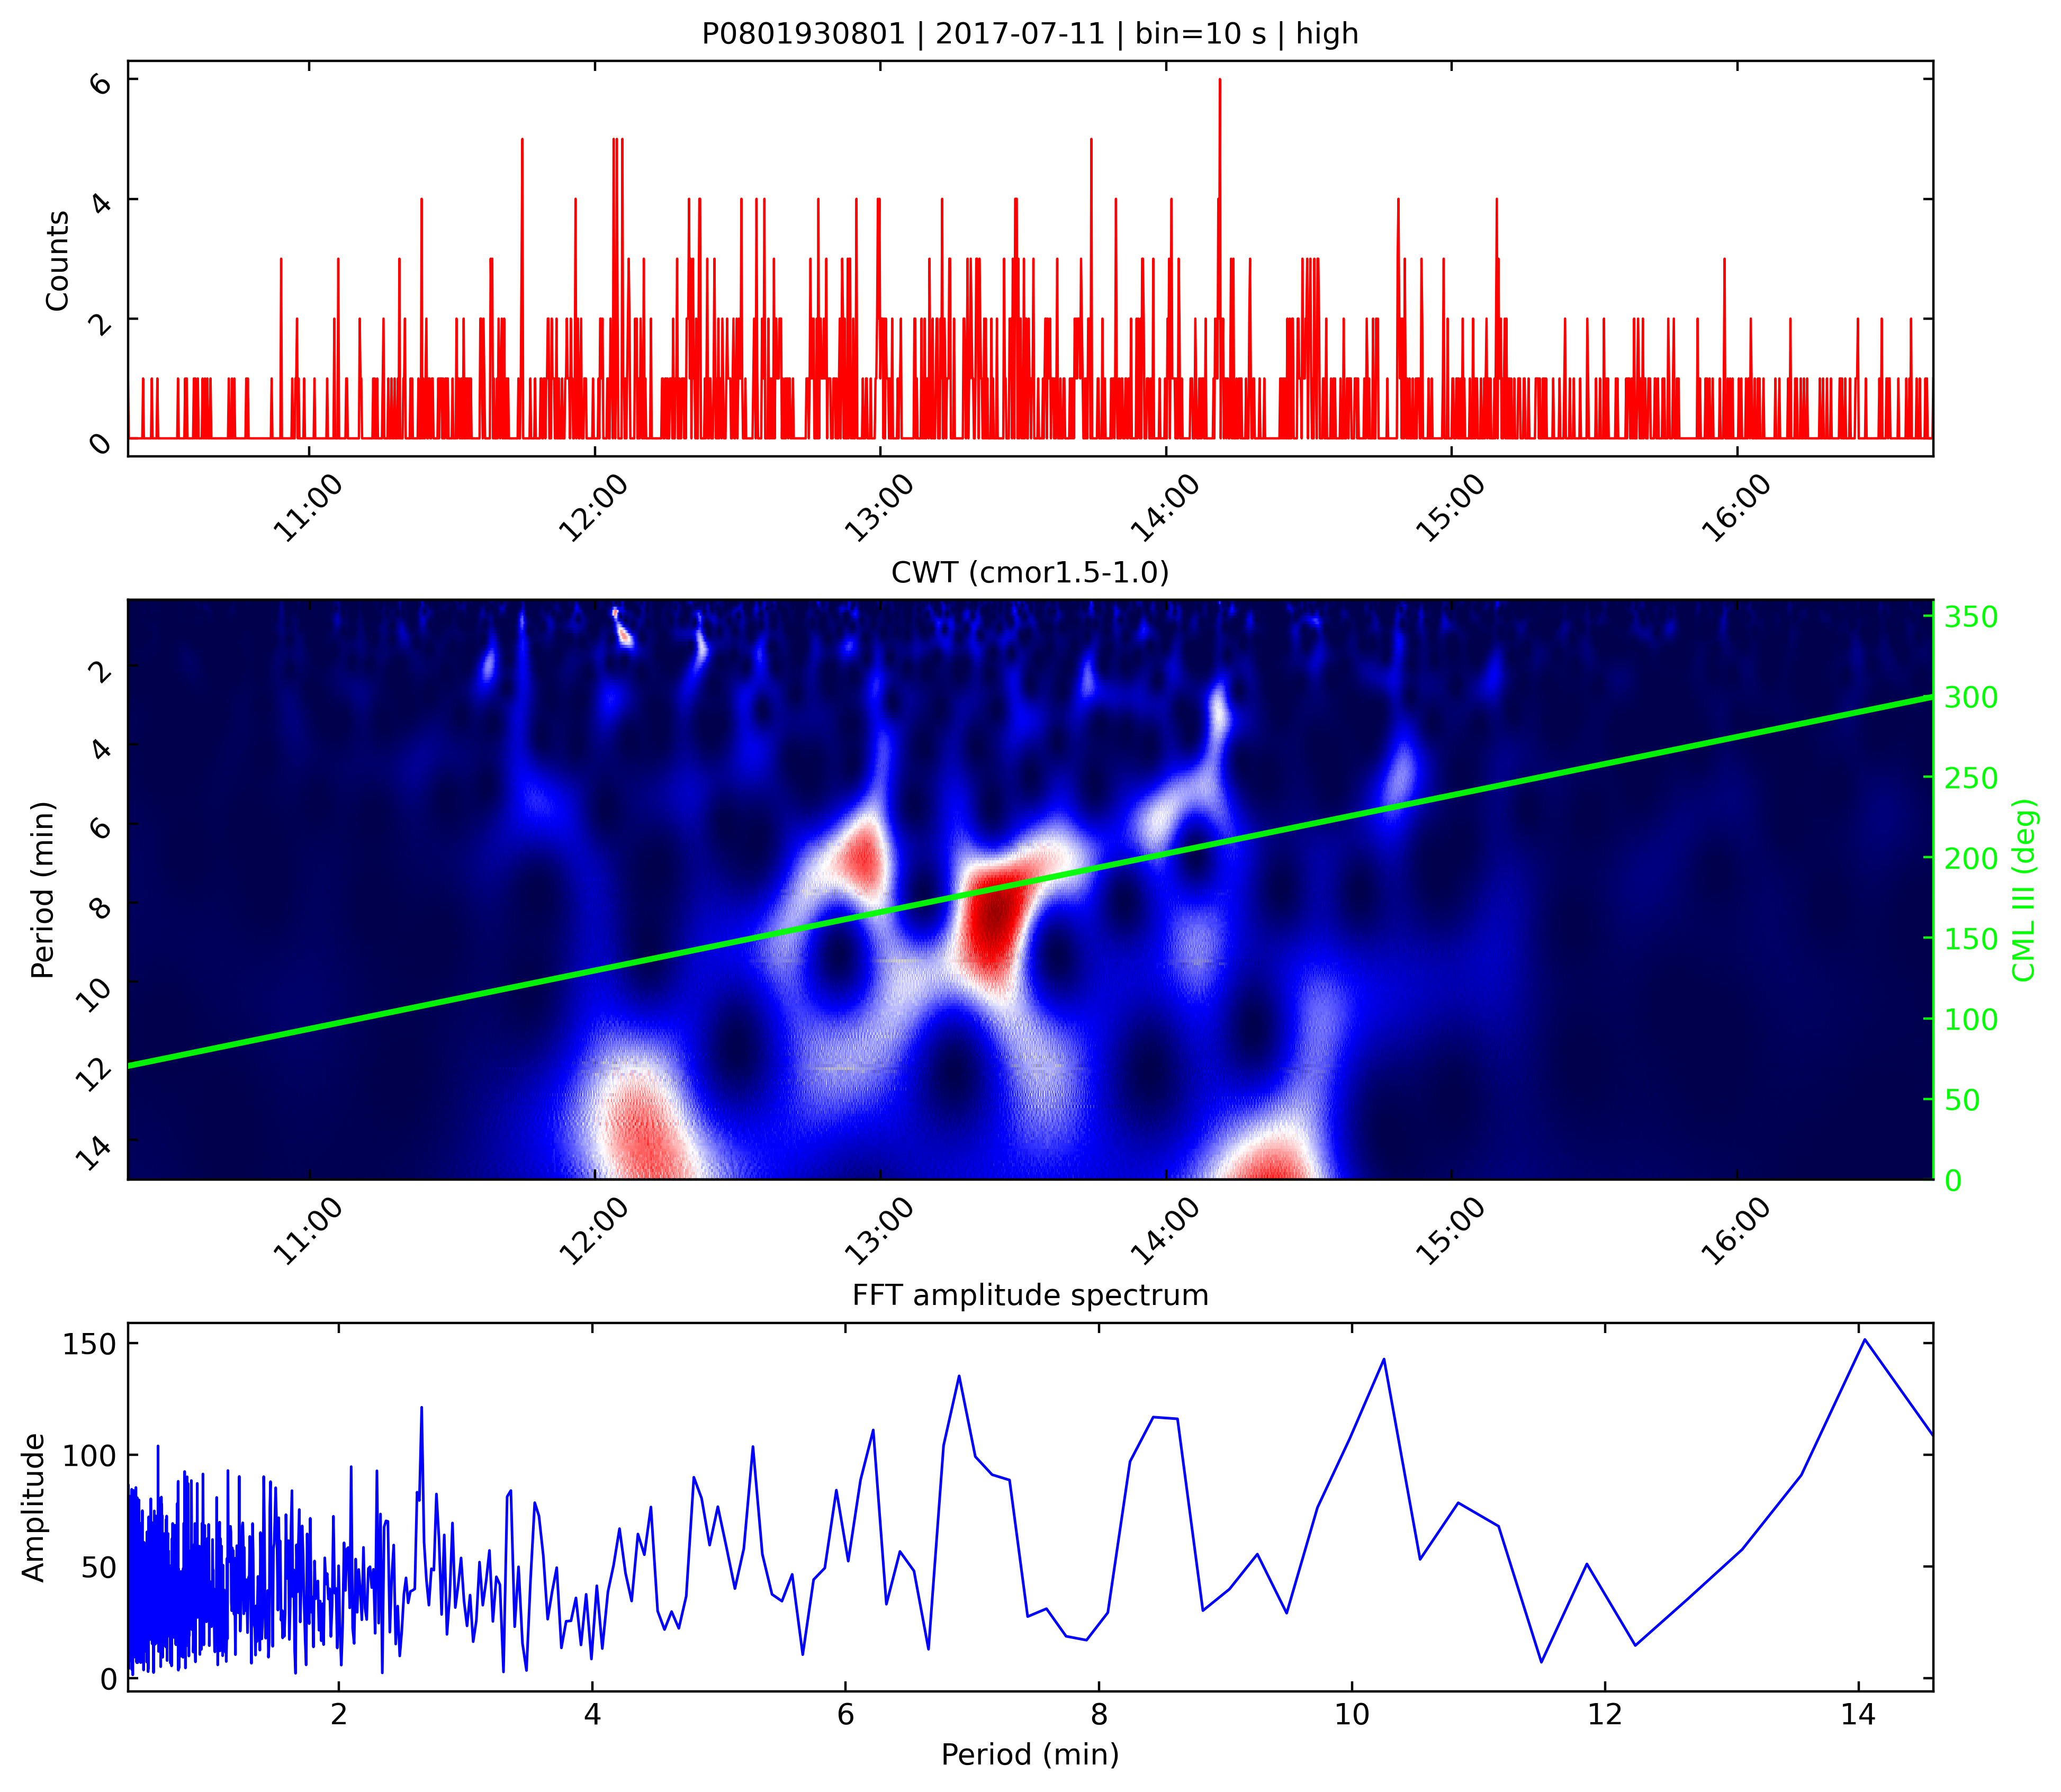

Finished P0801930801 | seg_bin=10 s | category=high


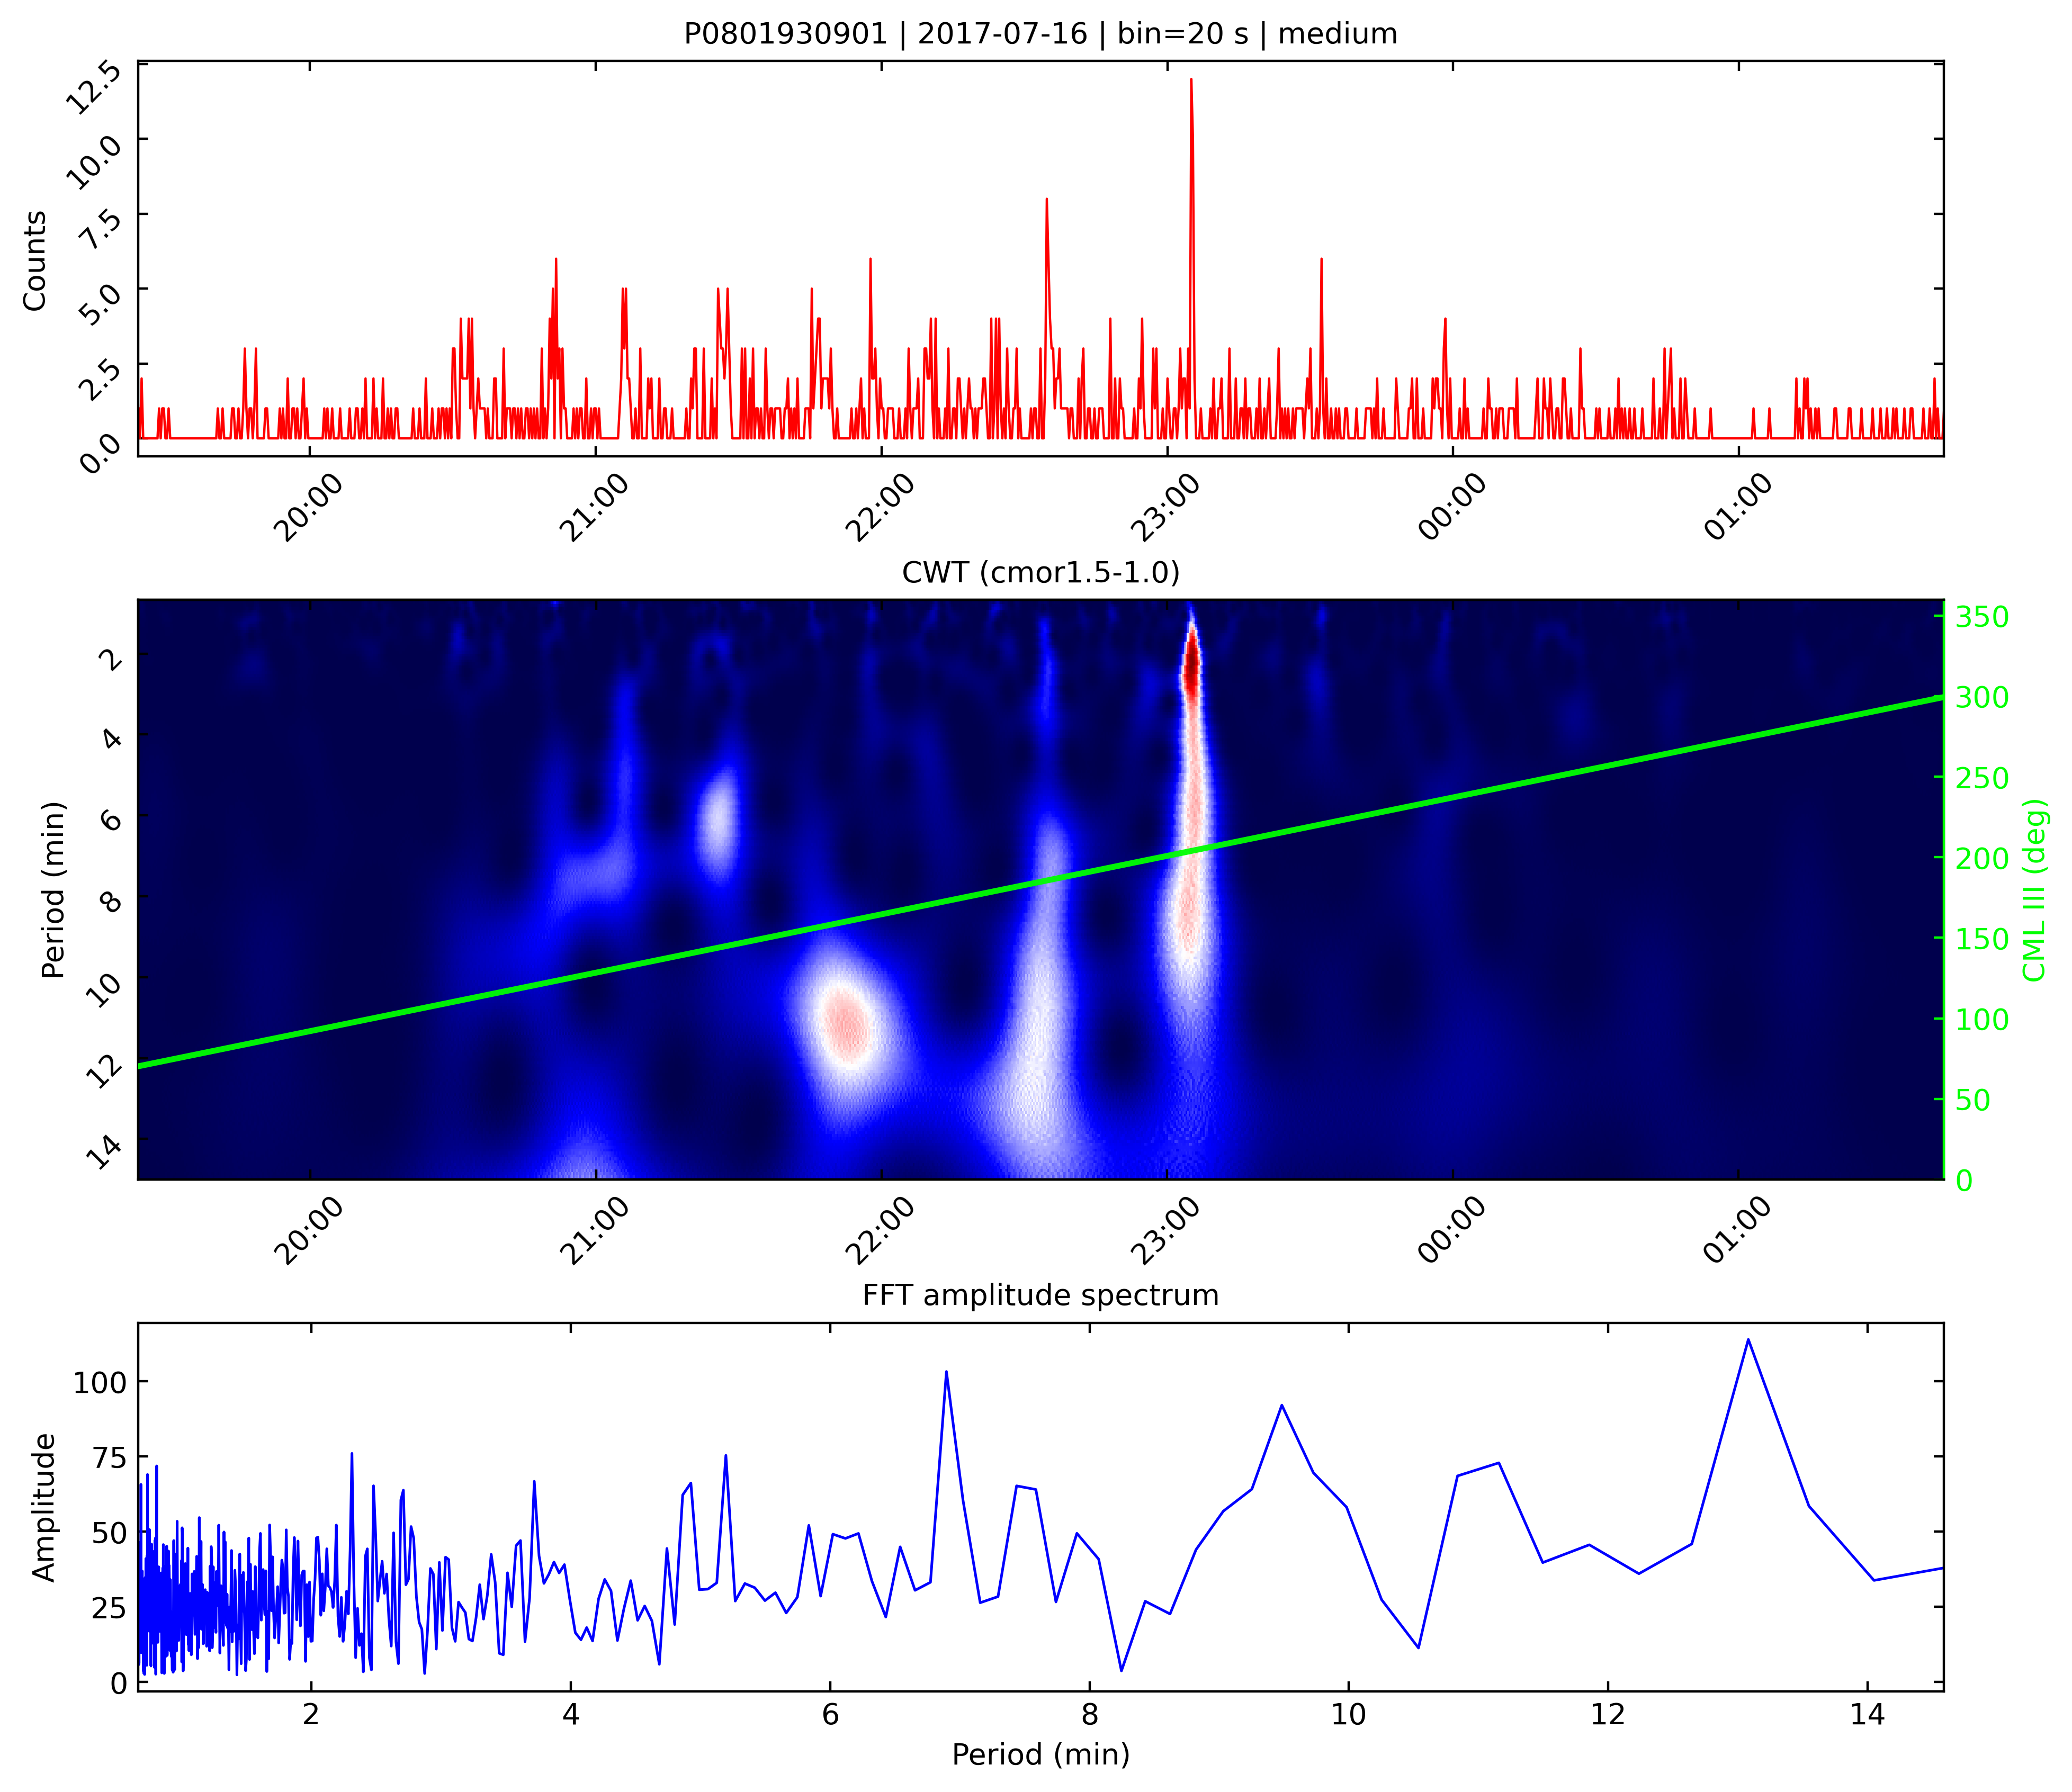

Finished P0801930901 | seg_bin=20 s | category=medium


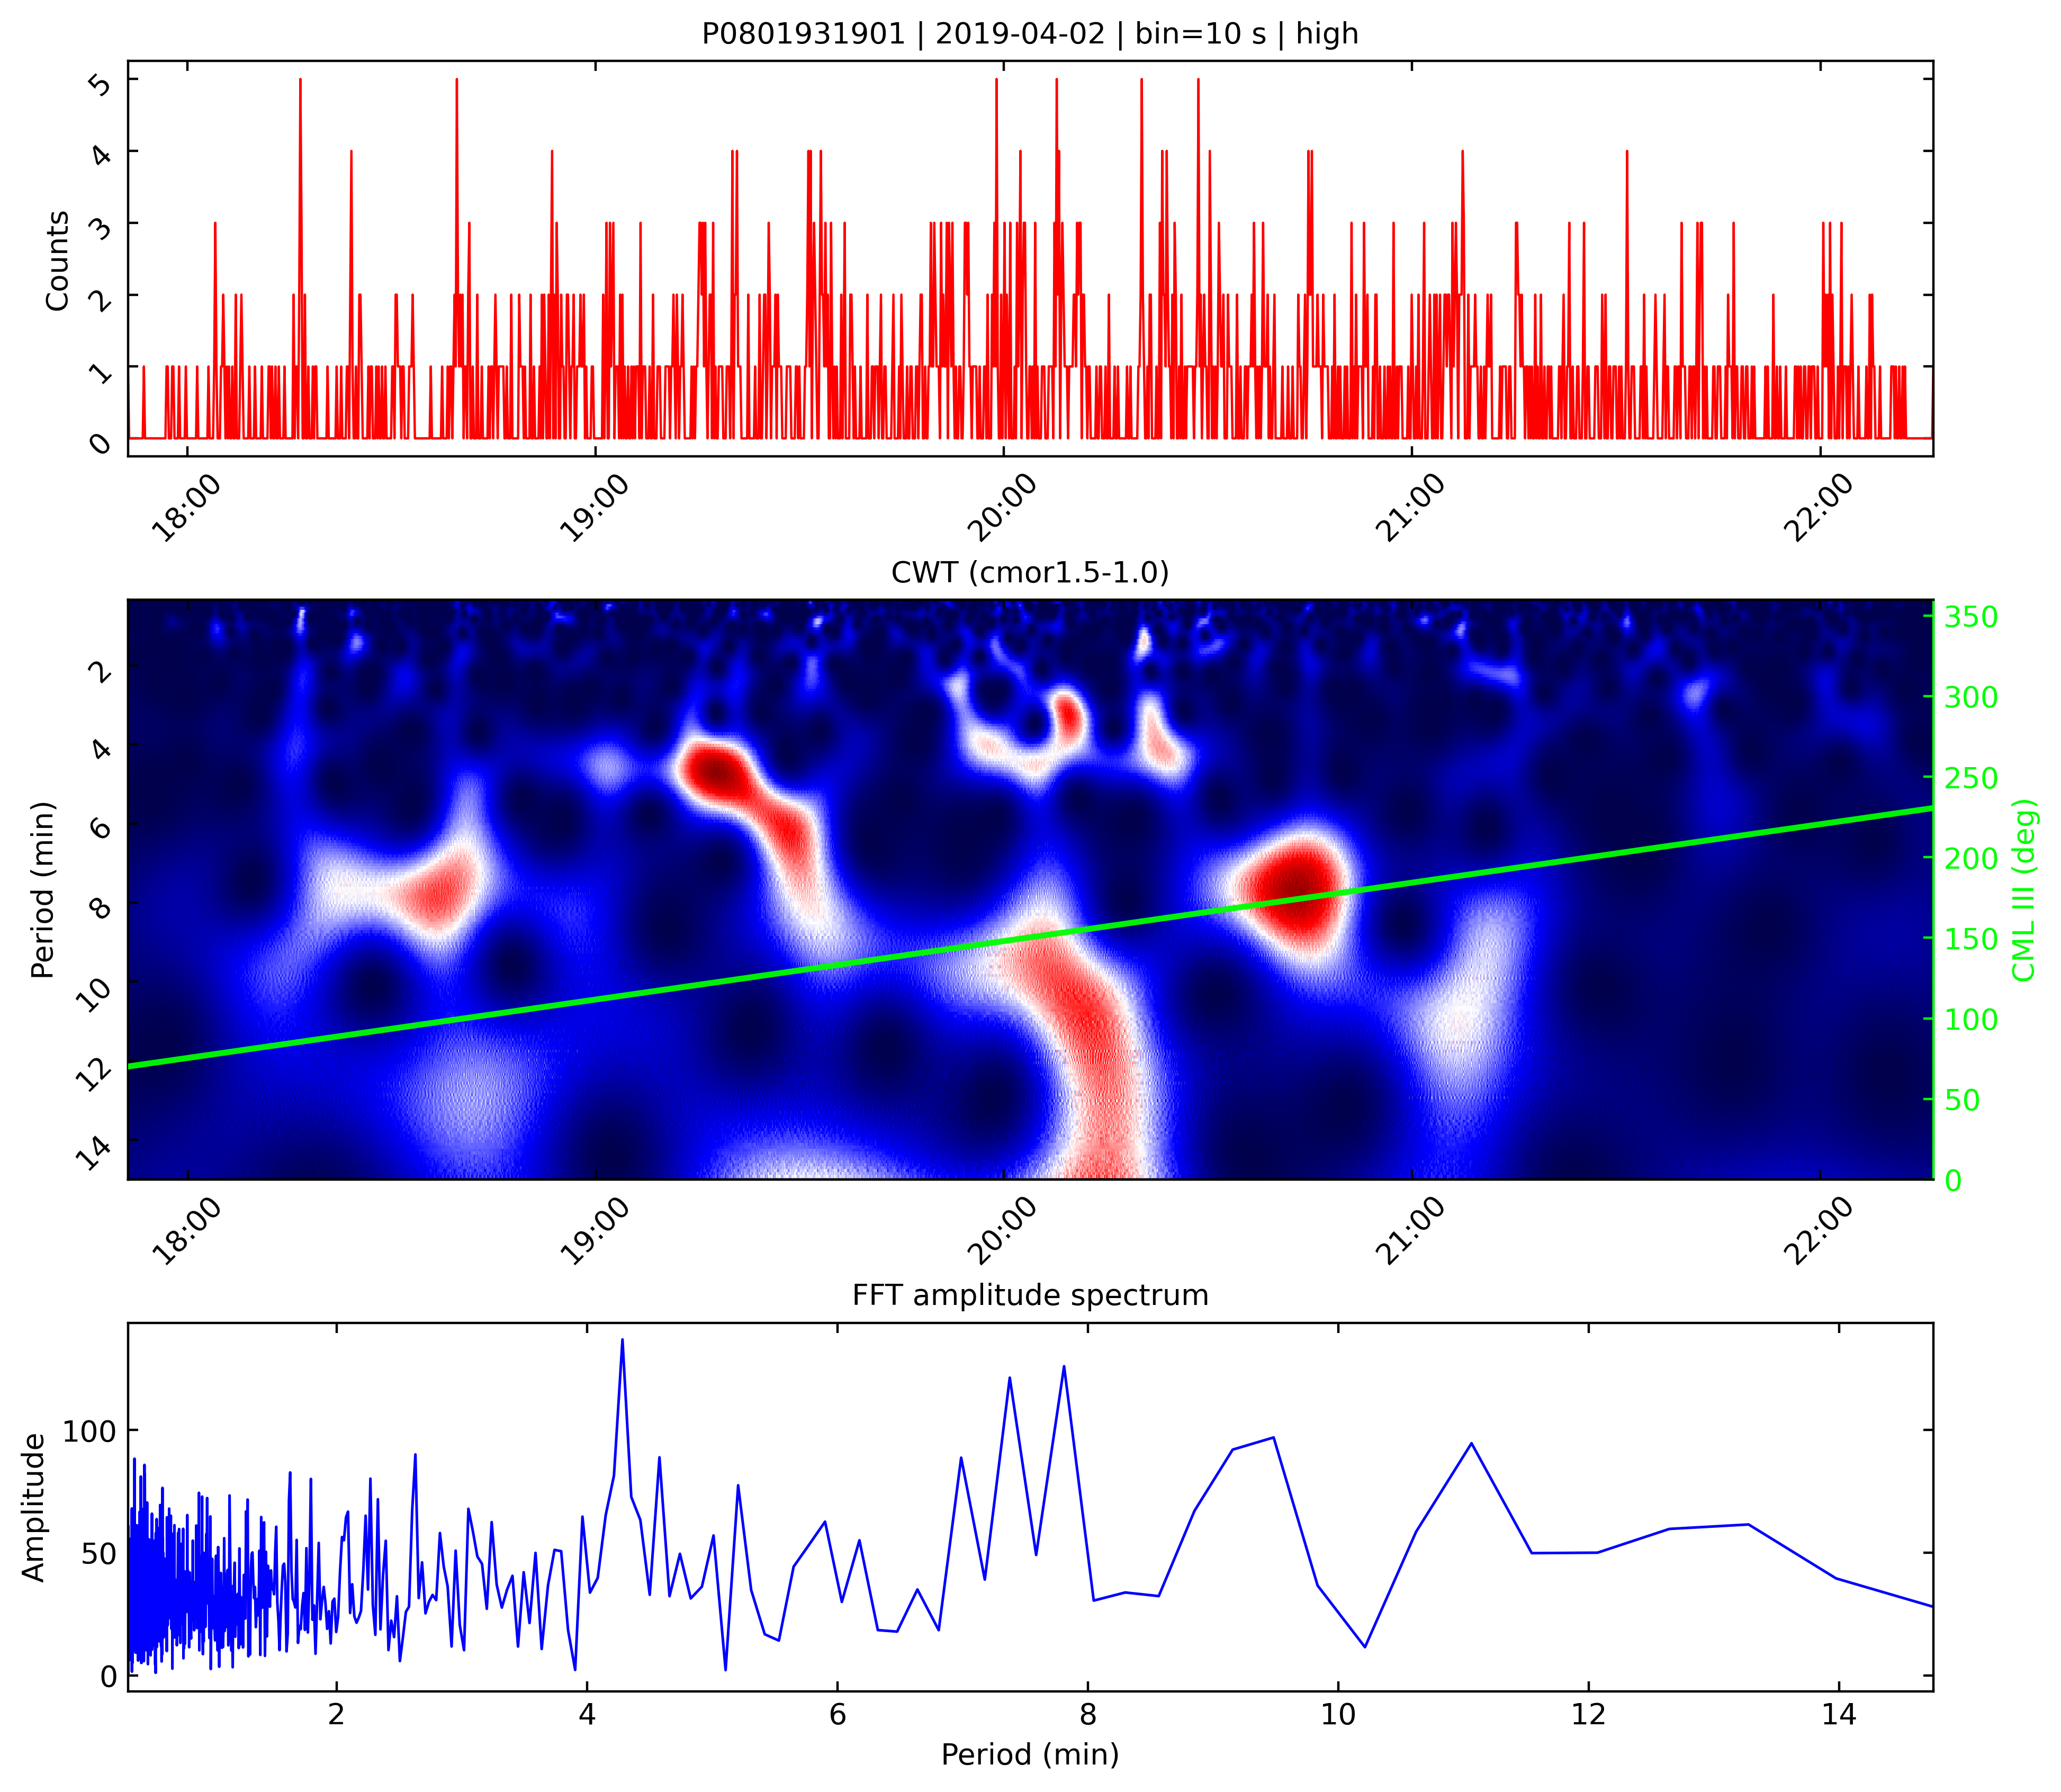

Finished P0801931901 | seg_bin=10 s | category=high


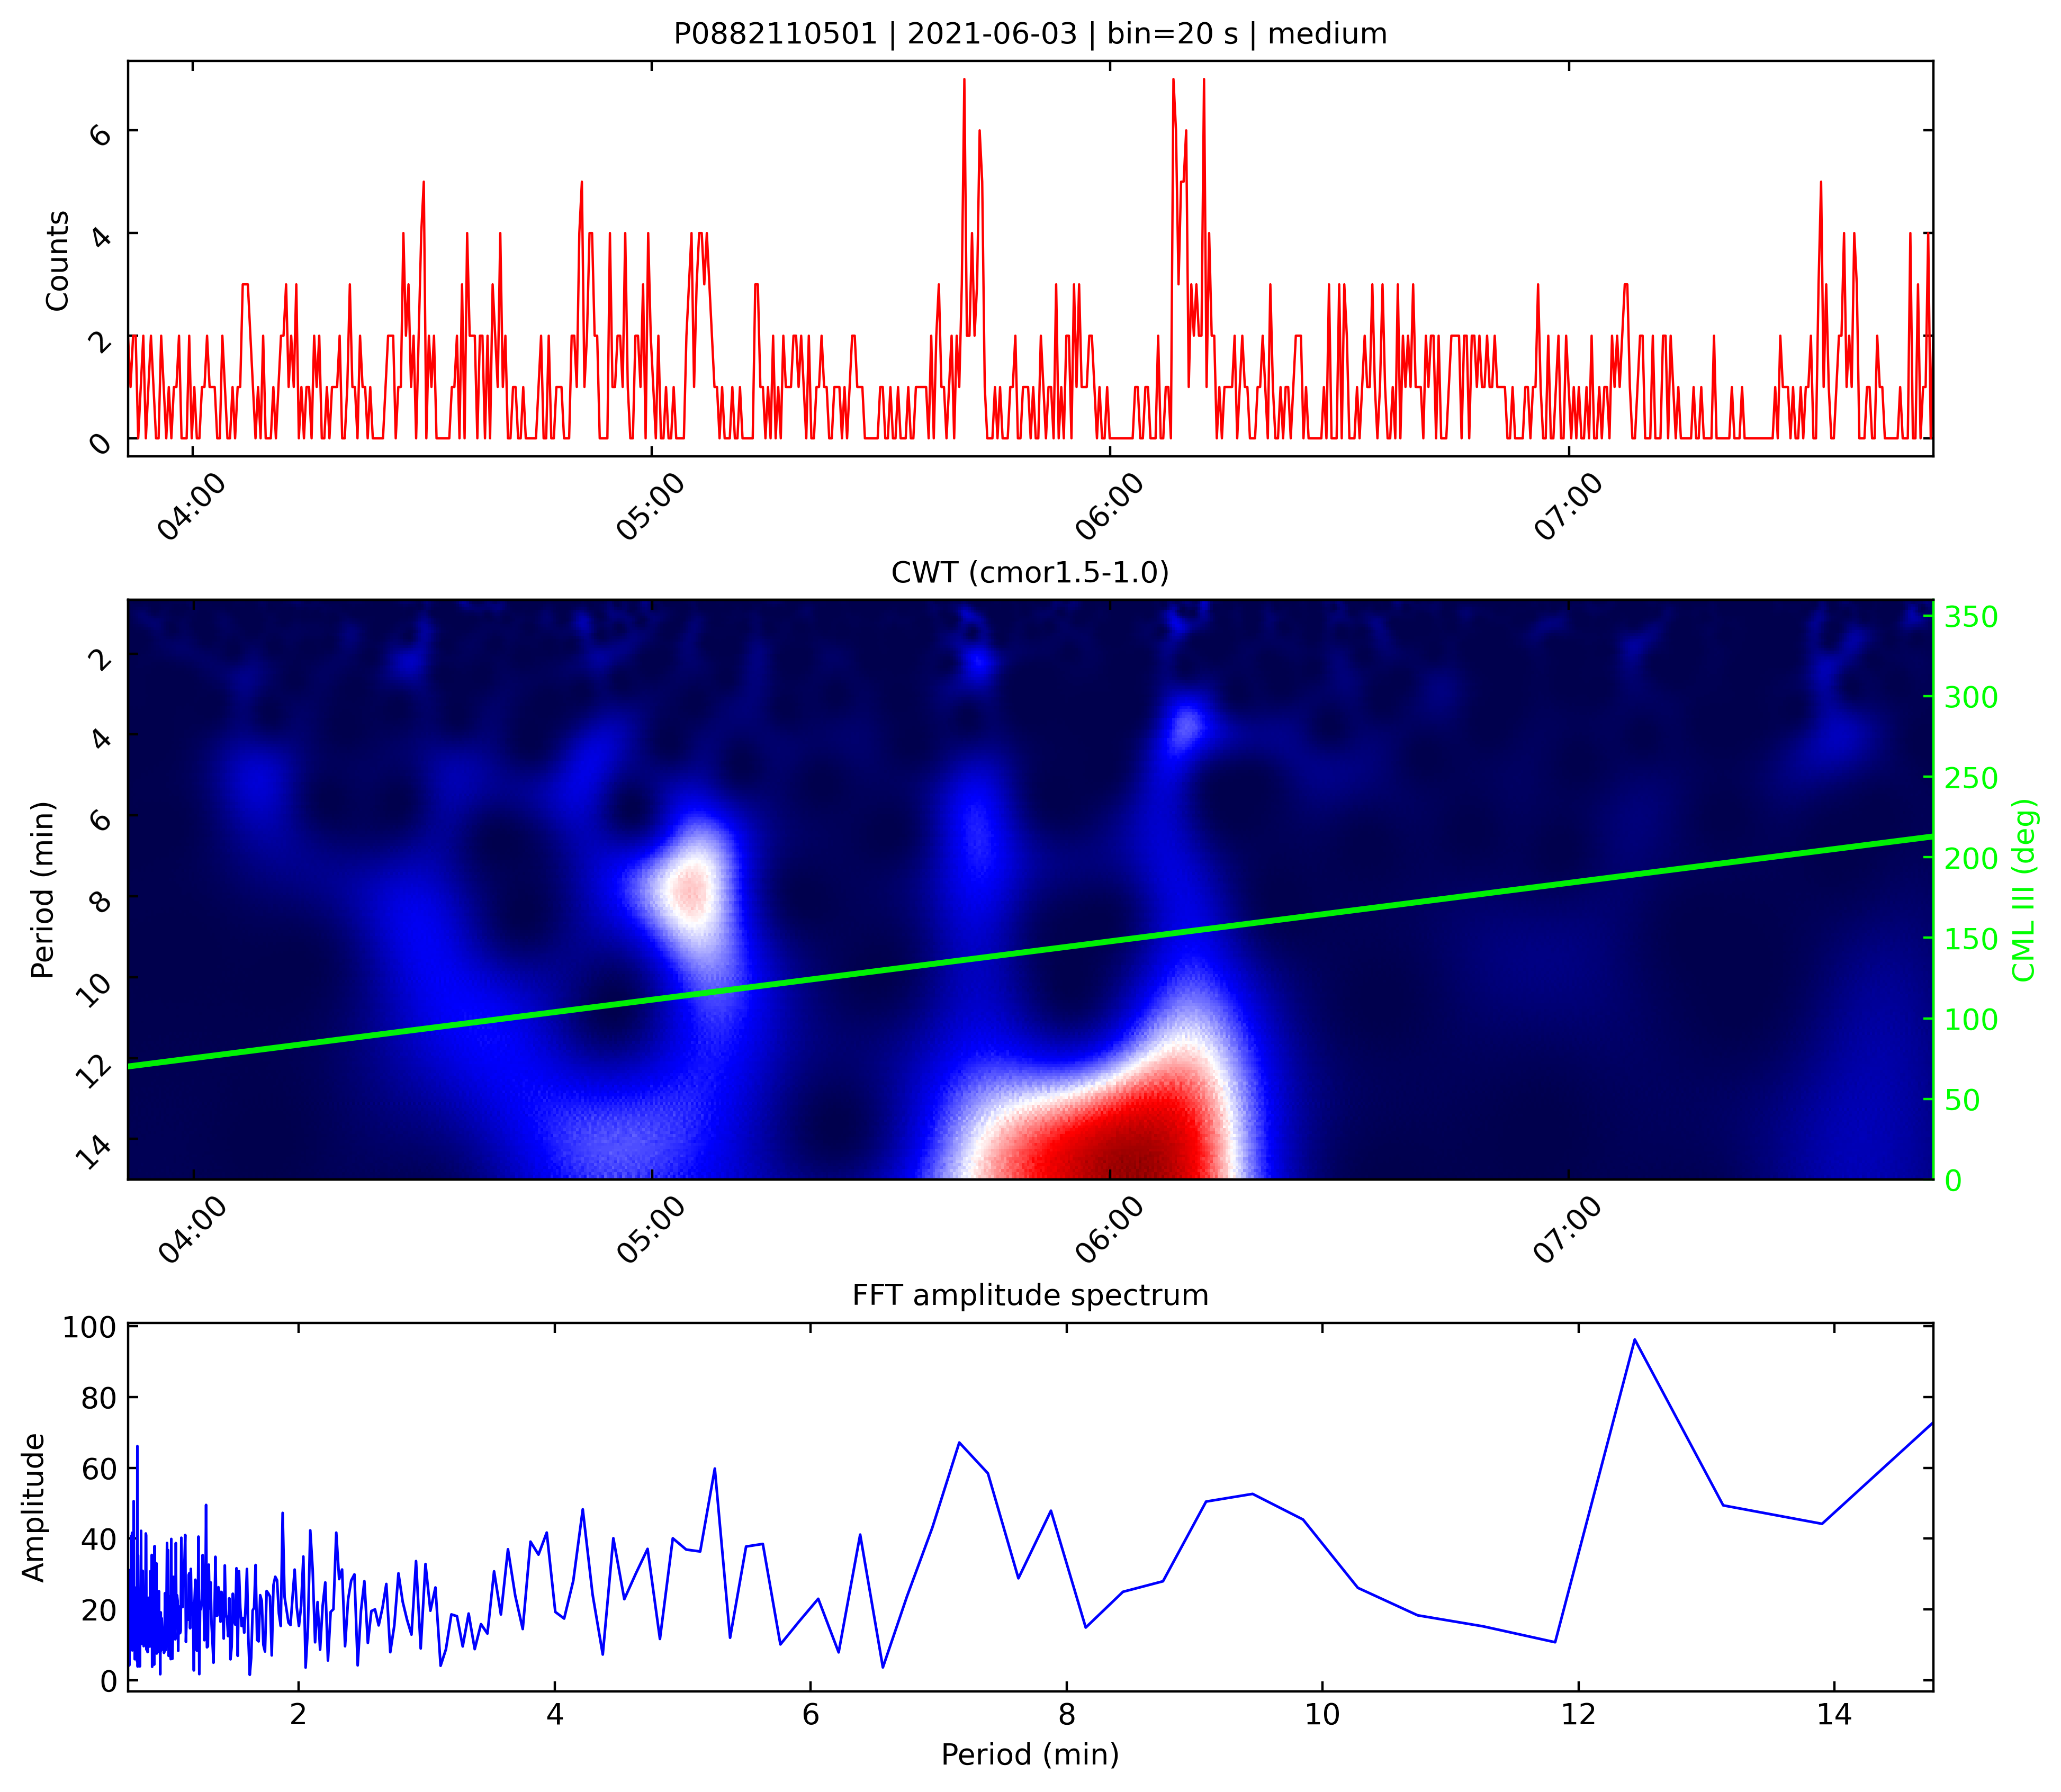

Finished P0882110501 | seg_bin=20 s | category=medium


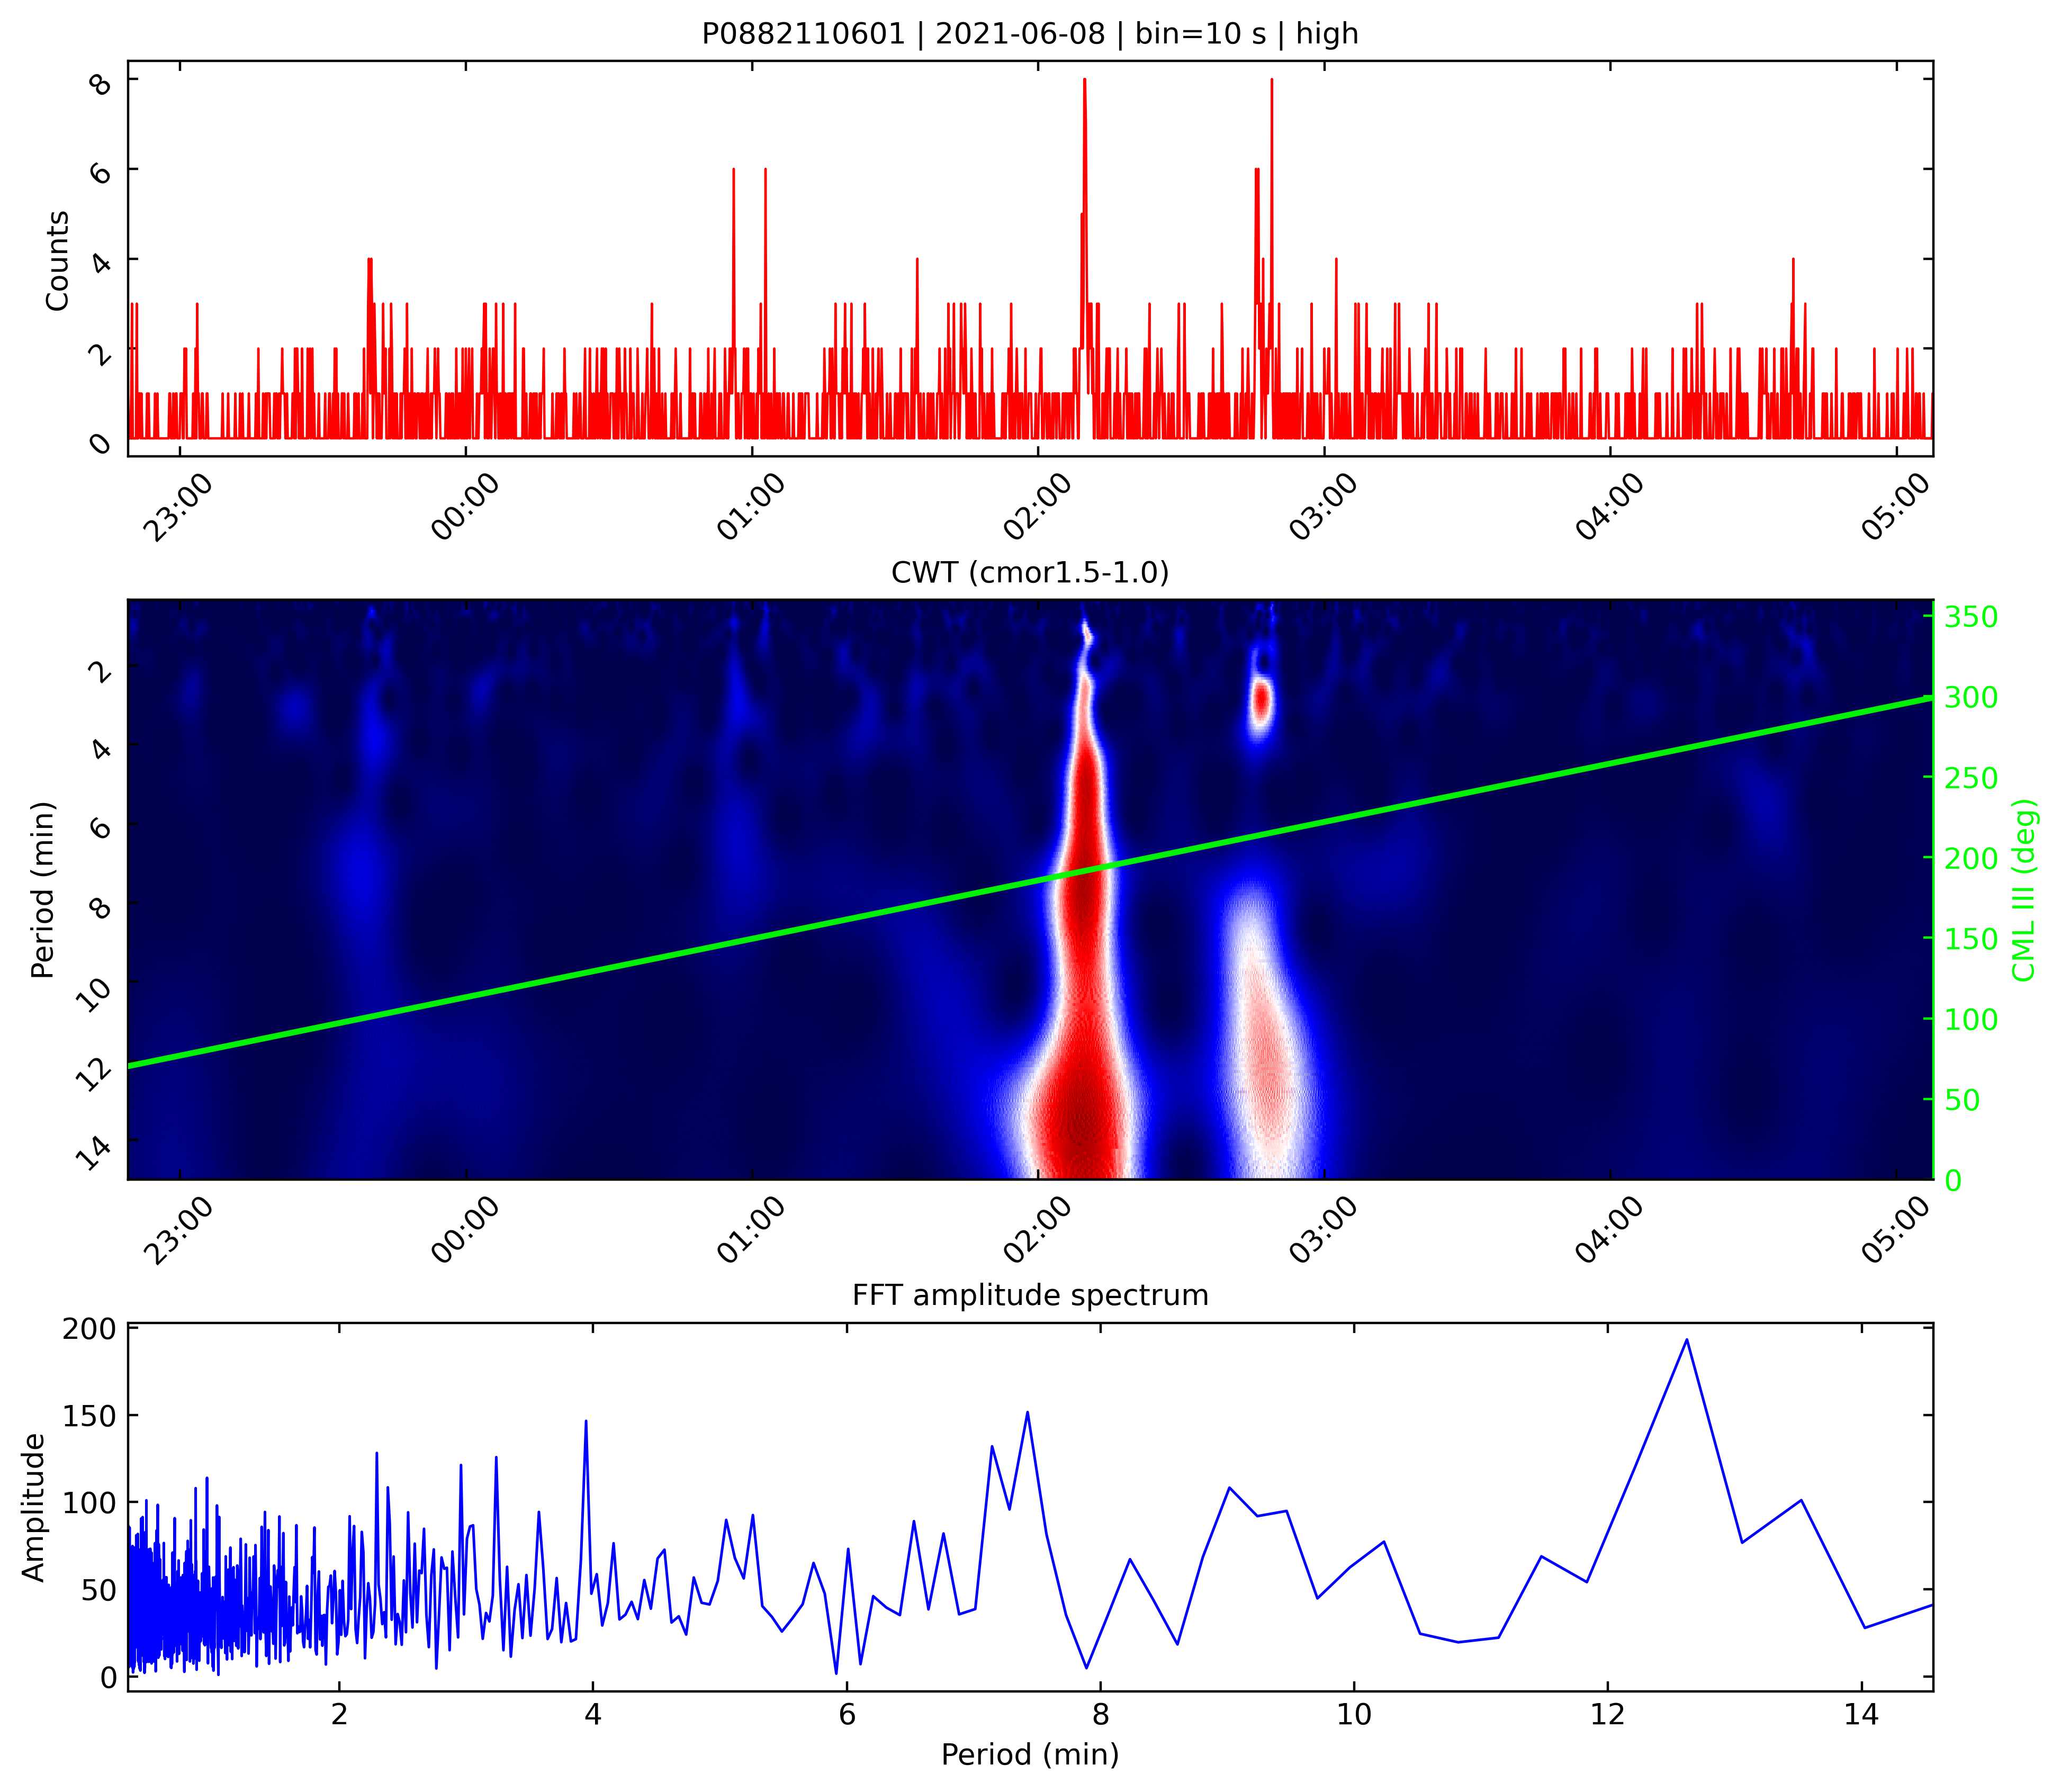

Finished P0882110601 | seg_bin=10 s | category=high


In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pywt
import spiceypy as sp

from typing import Optional, Dict
from astropy.table import Table
from astropy.time import Time
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
import astropy.units as u

from matplotlib.dates import DateFormatter, HourLocator
import warnings
warnings.filterwarnings("ignore")


# ─── USER SETTINGS ────────────────────────────────────────────────────────────
tick_interval_h = 1

ident = ['P0801930801', 'P0801930901', 'P0801931901', 'P0882110501', 'P0882110601']
TARGET_SEGMENTS = {
    'P0801930801': 2,
    'P0801930901': 1,
    'P0801931901': 3,
    'P0882110501': 3,
    'P0882110601': 5
}

base_bin_size = 10
data_dir = 'Data_Files/Fenn_Data/'
kernel_dir = "SPICE KERNELS"


# ─── SPICE SETUP ──────────────────────────────────────────────────────────────
def ensure_spice_kernels_loaded(kernel_dir: str):
    required = ["naif0012.tls", "de440.bsp", "jup365.bsp"]

    pck11 = os.path.join(kernel_dir, "pck00011.tpc")
    pck10 = os.path.join(kernel_dir, "pck00010.tpc")

    sp.kclear()

    for fname in required:
        path = os.path.join(kernel_dir, fname)
        if not os.path.exists(path):
            raise FileNotFoundError(f"Missing SPICE kernel: {path}")
        sp.furnsh(path)

    if os.path.exists(pck11):
        sp.furnsh(pck11)
    elif os.path.exists(pck10):
        sp.furnsh(pck10)
    else:
        raise FileNotFoundError(
            f"Need either {os.path.join(kernel_dir, 'pck00011.tpc')} "
            f"or {os.path.join(kernel_dir, 'pck00010.tpc')}"
        )


# ─── IO + PREP ────────────────────────────────────────────────────────────────
def load_combined_times(obs_id: str, data_dir: str):
    """
    Read all three EPIC cameras, correct for Jupiter–Earth light travel time,
    and return:
      times_datetime : ndarray[datetime]
      times_cxcsec   : ndarray[float]
    """
    files = [f'{data_dir}EPIC_{obs_id}_{cam}_North_RFT.fit' for cam in ['PN', 'M1', 'M2']]
    list_dt, list_cxc = [], []

    for file in files:
        data = Table.read(file, format="fits")

        t = Time(data['TIME'], format='cxcsec', scale='tt')
        with solar_system_ephemeris.set('de432s'):
            jup = get_body_barycentric('jupiter', t)
            xmm = get_body_barycentric('earth', t)  # approximate XMM as Earth-based

        distance_au = (jup - xmm).norm()
        light_time_s = (distance_au.to('m') / c).to('s').value

        corrected_t = t - light_time_s * u.s
        list_dt.append(corrected_t.datetime)
        list_cxc.append(corrected_t.cxcsec)

    return np.hstack(list_dt), np.hstack(list_cxc)


def find_gaps(times_cxcsec: np.ndarray, threshold: float = 3600.0):
    """
    Identify indices where the gap between consecutive times > threshold seconds.
    Returns:
      gaps    : list of (gap_start, gap_end) in cxcsec
      indices : ndarray of indices i such that times[i+1]-times[i] > threshold
    """
    dt = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    gaps = [(times_cxcsec[i], times_cxcsec[i + 1]) for i in indices]
    return gaps, indices


# ─── BINNING ──────────────────────────────────────────────────────────────────
def bin_photon_times(photon_times: np.ndarray, bin_size: float):
    """
    Bin photon_times (CXC seconds) into bins of width=bin_size seconds.
    Returns:
      centers_cxcsec, counts
    """
    start = float(np.nanmin(photon_times))
    end = float(np.nanmax(photon_times))
    bins = np.arange(start, end + bin_size, bin_size)
    counts, edges = np.histogram(photon_times, bins=bins)
    centers = edges[:-1] + 0.5 * bin_size
    return centers, counts


def categorize_segment(counts: np.ndarray, low_thresh: float = 300, high_thresh: float = 1000):
    total = float(np.sum(counts))
    if total < low_thresh:
        return 'low'
    elif total < high_thresh:
        return 'medium'
    return 'high'


def dynamic_bin_size(category: str, base_bin: int = 120):
    if category == 'low':
        return base_bin * 4
    elif category == 'medium':
        return base_bin * 2
    return base_bin


def prepare_segment_bins(raw_segment: np.ndarray, base_bin: int):
    """
    1) initial bin with base_bin to categorise
    2) choose seg_bin via dynamic_bin_size
    3) re-bin with seg_bin
    """
    _, counts0 = bin_photon_times(raw_segment, base_bin)
    category = categorize_segment(counts0)

    seg_bin = dynamic_bin_size(category, base_bin)
    hist_centers, hist_counts = bin_photon_times(raw_segment, seg_bin)
    return seg_bin, hist_centers, hist_counts, category


# ─── CML HELPERS ──────────────────────────────────────────────────────────────
def cxcsec_to_et(cxcsec: np.ndarray) -> np.ndarray:
    """
    Convert CXC TT seconds to SPICE ET (~TDB seconds past J2000).
    """
    t = Time(cxcsec, format='cxcsec', scale='tt')
    t_tdb = t.tdb
    et = (t_tdb.jd - 2451545.0) * 86400.0
    return np.asarray(et, dtype=float)


def cml_from_hist_centers(hist_centers: np.ndarray) -> np.ndarray:
    """
    Compute Jupiter CML (System III west longitude) at each lightcurve bin center.
    """
    et_array = cxcsec_to_et(hist_centers)
    cml_deg = np.empty(len(et_array), dtype=float)

    for i, et in enumerate(et_array):
        state, _ = sp.spkezr("EARTH", float(et), "IAU_JUPITER", "NONE", "JUPITER")
        x, y, z = state[:3]
        r, lon_east_rad, lat_rad = sp.reclat(np.array([x, y, z]))
        lon_east_deg = np.degrees(lon_east_rad) % 360.0

        # Convert east-positive IAU longitude to west-positive CML
        cml_deg[i] = (360.0 - lon_east_deg) % 360.0

    return cml_deg


def break_cml_wraps(cml_deg: np.ndarray, jump_thresh: float = 180.0) -> np.ndarray:
    """
    Replace wrap points with NaN so matplotlib does not draw long diagonal lines
    across the 360->0 discontinuity.
    """
    cml_plot = np.asarray(cml_deg, dtype=float).copy()
    jumps = np.where(np.abs(np.diff(cml_plot)) > jump_thresh)[0]
    for j in jumps:
        cml_plot[j + 1] = np.nan
    return cml_plot


# ─── PREPROCESSING ────────────────────────────────────────────────────────────
def preprocess_lightcurve(hist_counts: np.ndarray, detrend: bool = True, standardize: bool = True):
    """
    Simple preprocessing for FFT/CWT:
      - optional linear detrend
      - mean removal
      - optional standardization
    """
    y = hist_counts.astype(float).copy()
    x = np.arange(len(y), dtype=float)

    if detrend and len(y) >= 2:
        p = np.polyfit(x, y, 1)
        trend = np.polyval(p, x)
        y = y - trend

    y = y - np.nanmean(y)

    if standardize:
        std = np.nanstd(y)
        if std > 0:
            y = y / std

    return y


# ─── FFT ──────────────────────────────────────────────────────────────────────
def compute_lightcurve_fft(
    hist_counts: np.ndarray,
    seg_bin: float,
    period_min_min: Optional[float] = None,
    period_max_min: float = 15.0,
):
    """
    Compute a simple FFT amplitude spectrum on the binned lightcurve.

    Returns:
      periods_min, amplitudes
    """
    y = preprocess_lightcurve(hist_counts, detrend=True, standardize=True)
    n = len(y)

    if n < 4:
        raise ValueError("Not enough bins for FFT.")

    dt = float(seg_bin)  # seconds

    fft_vals = np.fft.rfft(y)
    freqs_hz = np.fft.rfftfreq(n, d=dt)

    # drop DC
    keep = freqs_hz > 0
    freqs_hz = freqs_hz[keep]
    fft_vals = fft_vals[keep]

    periods_min = (1.0 / freqs_hz) / 60.0
    amplitudes = np.abs(fft_vals)

    if period_min_min is None:
        period_min_min = 2.0 * seg_bin / 60.0

    mask = (periods_min >= period_min_min) & (periods_min <= period_max_min)

    periods_min = periods_min[mask]
    amplitudes = amplitudes[mask]

    order = np.argsort(periods_min)
    return periods_min[order], amplitudes[order]


# ─── CWT (CMORL / COMPLEX MORLET) ────────────────────────────────────────────
def compute_lightcurve_cwt(
    hist_counts: np.ndarray,
    seg_bin: float,
    period_min_min: Optional[float] = None,
    period_max_min: float = 15.0,
    n_periods: int = 200,
    wavelet_name: str = 'cmor1.5-1.0',
):
    """
    Compute complex Morlet CWT on the binned lightcurve.

    Returns:
      periods_min
      power
      times_min_from_start
      coeffs
    """
    y = preprocess_lightcurve(hist_counts, detrend=True, standardize=True)
    n = len(y)

    if n < 4:
        raise ValueError("Not enough bins for CWT.")

    dt = float(seg_bin)
    sampling_period = dt

    if period_min_min is None:
        period_min_min = 2.0 * seg_bin / 60.0

    periods_min = np.linspace(period_min_min, period_max_min, n_periods)
    periods_s = periods_min * 60.0

    wavelet = pywt.ContinuousWavelet(wavelet_name)
    central_freq = pywt.central_frequency(wavelet)
    scales = periods_s * central_freq / sampling_period

    coeffs, freqs_hz = pywt.cwt(y, scales, wavelet, sampling_period=sampling_period)
    power = np.abs(coeffs) ** 2
    times_min_from_start = np.arange(n) * dt / 60.0

    return periods_min, power, times_min_from_start, coeffs


# ─── PLOTTING ─────────────────────────────────────────────────────────────────
def plot_lightcurve_subplot(ax, hist_centers, hist_counts, seg_bin, category,
                            obs_id, start_iso, end_iso):
    hist_dt = Time(hist_centers, format='cxcsec').datetime
    ax.plot(hist_dt, hist_counts, c='red', lw=0.8)

    title = f"{obs_id} | {start_iso[:10]} | bin={int(seg_bin)} s | {category}"
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("Counts")
    ax.set_xlim(hist_dt[0], hist_dt[-1])

    ax.xaxis.set_major_locator(HourLocator(interval=1))
    ax.xaxis.set_major_formatter(DateFormatter('%H:%M'))
    ax.tick_params(rotation=45, direction='in', top=True, right=True)


def plot_cwt_subplot(ax, hist_centers, periods_min, power, obs_id, wavelet_name, cml_deg=None):
    hist_dt = Time(hist_centers, format='cxcsec').datetime

    pcm = ax.pcolormesh(
        hist_dt,
        periods_min,
        power,
        shading='auto',
        cmap='seismic'
    )

    ax.set_ylabel("Period (min)")
    ax.set_title(f"CWT ({wavelet_name})", fontsize=10)
    ax.set_ylim(periods_min[0], periods_min[-1])
    ax.invert_yaxis()
    ax.xaxis.set_major_locator(HourLocator(interval=1))
    ax.xaxis.set_major_formatter(DateFormatter('%H:%M'))
    ax.tick_params(rotation=45, direction='in', top=True, right=True)

    # Overlay CML on right axis
    if cml_deg is not None:
        ax2 = ax.twinx()
        cml_plot = break_cml_wraps(cml_deg)

        ax2.plot(
            hist_dt,
            cml_plot,
            color='lime',
            lw=2.0,
            alpha=0.95,
            zorder=10
        )
        ax2.set_ylabel("CML III (deg)", color='lime')
        ax2.set_ylim(0, 360)
        ax2.tick_params(axis='y', colors='lime', direction='in')
        ax2.spines['right'].set_color('lime')
        ax2.yaxis.label.set_color('lime')

    return pcm


def plot_fft_subplot(ax, periods_min, amplitudes):
    ax.plot(periods_min, amplitudes, lw=0.9, c='blue')
    ax.set_title("FFT amplitude spectrum", fontsize=10)
    ax.set_xlabel("Period (min)")
    ax.set_ylabel("Amplitude")
    ax.tick_params(direction='in', top=True, right=True)

    if len(periods_min) > 0:
        ax.set_xlim(periods_min.min(), periods_min.max())


# ─── FINAL WRAPPER ────────────────────────────────────────────────────────────
def run_xmm_lc_segment_analysis_cwt_fft(
    obs_id: str,
    data_dir: str = "Data_Files/Fenn_Data/",
    kernel_dir: str = "SPICE_KERNELS",
    base_bin_size: int = 10,
    gap_threshold_s: int = 3600,
    target_segments: Optional[Dict[str, int]] = None,
    save_path: Optional[str] = None,
    show: bool = True,
    dpi: int = 200,
    period_max_min: float = 15.0,
    period_min_min: Optional[float] = None,
    wavelet_name: str = 'cmor1.5-1.0',
    n_cwt_periods: int = 200,
):
    """
    End-to-end wrapper for:
      - load combined EPIC photon times
      - gap-split into segments
      - optional 1-based segment selection
      - dynamic binning
      - lightcurve + cmor CWT + FFT
      - CML overlay on wavelet panel
    """
    if target_segments is None:
        target_segments = {}

    ensure_spice_kernels_loaded(kernel_dir)

    # Load + sort
    _, times_cxc = load_combined_times(obs_id, data_dir)
    if times_cxc.size < 10:
        raise ValueError(f"{obs_id}: not enough events after loading (N={times_cxc.size}).")

    order = np.argsort(times_cxc)
    t_sorted = times_cxc[order]

    # Gap split
    _, gap_idx = find_gaps(t_sorted, threshold=float(gap_threshold_s))
    split_pts = np.concatenate(([0], gap_idx + 1, [len(t_sorted)]))

    segments = []
    seg_times_iso = []
    for i in range(len(split_pts) - 1):
        seg = t_sorted[split_pts[i]: split_pts[i + 1]]
        if seg.size > 5:
            segments.append(seg)
            seg_times_iso.append((
                Time(seg[0], format='cxcsec').iso,
                Time(seg[-1], format='cxcsec').iso
            ))

    if len(segments) == 0:
        raise ValueError(f"{obs_id}: no valid segments after gap-splitting.")

    selected_1based = target_segments.get(obs_id, None)
    if selected_1based is not None:
        k = selected_1based - 1
        if not (0 <= k < len(segments)):
            raise ValueError(
                f"{obs_id}: requested segment {selected_1based} "
                f"but only {len(segments)} segments exist."
            )
        segments = [segments[k]]
        seg_times_iso = [seg_times_iso[k]]

    seg = segments[0]
    start_iso, end_iso = seg_times_iso[0]

    # Binning
    seg_bin, hist_centers, hist_counts, category = prepare_segment_bins(seg, base_bin_size)

    if period_min_min is None:
        period_min_min = 2.0 * seg_bin / 60.0

    # CML at the lightcurve bin centres
    cml_deg = cml_from_hist_centers(hist_centers)

    # CWT
    cwt_periods_min, cwt_power, cwt_times_min, cwt_coeffs = compute_lightcurve_cwt(
        hist_counts=hist_counts,
        seg_bin=seg_bin,
        period_min_min=period_min_min,
        period_max_min=period_max_min,
        n_periods=n_cwt_periods,
        wavelet_name=wavelet_name,
    )

    # FFT
    fft_periods_min, fft_amplitudes = compute_lightcurve_fft(
        hist_counts=hist_counts,
        seg_bin=seg_bin,
        period_min_min=period_min_min,
        period_max_min=period_max_min,
    )

    # Plot
    fig, (ax_lc, ax_cwt, ax_fft) = plt.subplots(
        3, 1,
        figsize=(11, 10),
        dpi=dpi,
        gridspec_kw={"height_ratios": [1.5, 2.2, 1.4], "hspace": 0.32}
    )

    plot_lightcurve_subplot(
        ax_lc, hist_centers, hist_counts, seg_bin, category, obs_id, start_iso, end_iso
    )
    ax_lc.set_xlabel("")

    pcm = plot_cwt_subplot(
        ax_cwt,
        hist_centers,
        cwt_periods_min,
        cwt_power,
        obs_id,
        wavelet_name,
        cml_deg=cml_deg
    )
    ax_cwt.set_xlabel("")

    # cbar = fig.colorbar(pcm, ax=ax_cwt, pad=0.02)
    # cbar.set_label("CWT power")

    plot_fft_subplot(ax_fft, fft_periods_min, fft_amplitudes)

    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, bbox_inches="tight")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return {
        "obs_id": obs_id,
        "selected_segment_1based": selected_1based,
        "start_iso": start_iso,
        "end_iso": end_iso,
        "category": category,
        "seg_bin_s": seg_bin,
        "hist_centers_cxcsec": hist_centers,
        "hist_counts": hist_counts,
        "cml_deg": cml_deg,
        "cwt_periods_min": cwt_periods_min,
        "cwt_power": cwt_power,
        "cwt_coeffs": cwt_coeffs,
        "fft_periods_min": fft_periods_min,
        "fft_amplitudes": fft_amplitudes,
        "n_segments_found": len(segments) if selected_1based is None else None,
    }


# ─── BATCH DRIVER ─────────────────────────────────────────────────────────────
if __name__ == "__main__":
    for obs_id in ident:
        out = run_xmm_lc_segment_analysis_cwt_fft(
            obs_id=obs_id,
            data_dir=data_dir,
            kernel_dir=kernel_dir,
            base_bin_size=base_bin_size,
            gap_threshold_s=3600,
            target_segments=TARGET_SEGMENTS,
            save_path=f"{obs_id}_lc_cwt_fft.png",
            show=True,
            dpi=400,
            period_max_min=15.0,
            period_min_min=None,
            wavelet_name='cmor1.5-1.0',
            n_cwt_periods=200,
        )
        print(
            f"Finished {obs_id} | seg_bin={out['seg_bin_s']} s | "
            f"category={out['category']}"
        )